In [1]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import pandas as pd
from pathlib import Path

In [2]:
path = "/Users/lukas/Workspace/Uni/BachelorsThesis/FICE/output/run_2026-01-04_15-22-00"
path = Path(path) / 'logs'

# Metrics (Overall)


In [3]:
test_data = pd.read_csv(path / 'test_metrics_per_graph.csv')
train_data = pd.read_csv(path / 'train_metrics_per_graph.csv')
print(test_data.head())


   epoch   dataset_name       loss           mse           mae          rmse  \
0      1      wn18rr_v4  19.286406  7.152179e+15  1.346714e+07  8.457055e+07   
1      1  wn18rr_v4_ind  11.562764  4.814145e+16  2.395098e+07  2.194116e+08   
2      1           swdf   9.433142  1.461058e+11  8.336207e+04  3.822379e+05   
3      1   fb237_v4_ind  20.267632  3.268415e+16  2.829007e+07  1.807876e+08   
4      1       wikidata  19.461562  5.090067e+10  5.803343e+04  2.256118e+05   

       q_error  
0   742.701819  
1   328.716500  
2   220.040069  
3  3579.592295  
4  1202.206397  


# Metric Visualizations

Separate plots for each metric, showing test and train data in different figures.

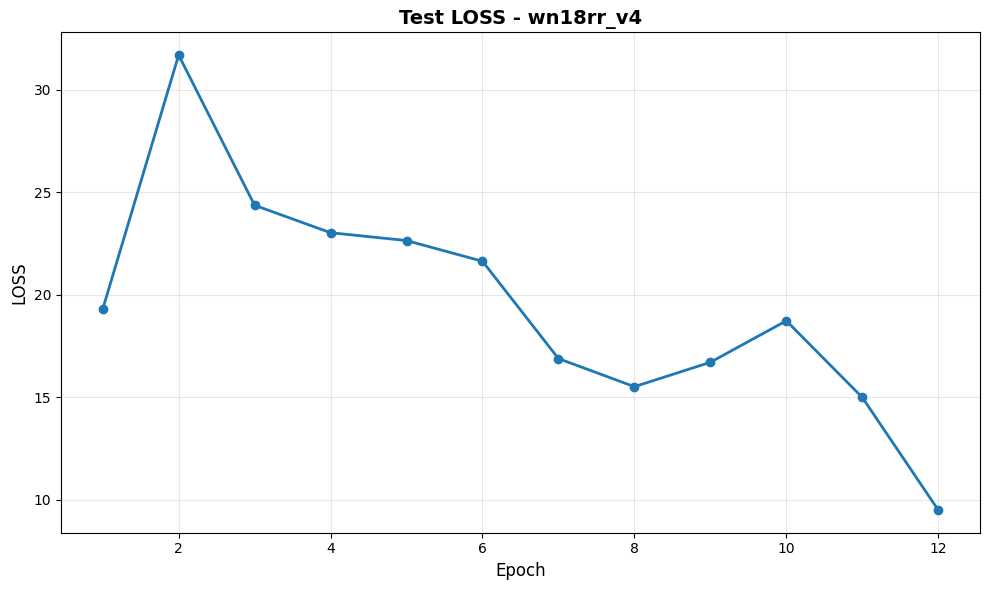

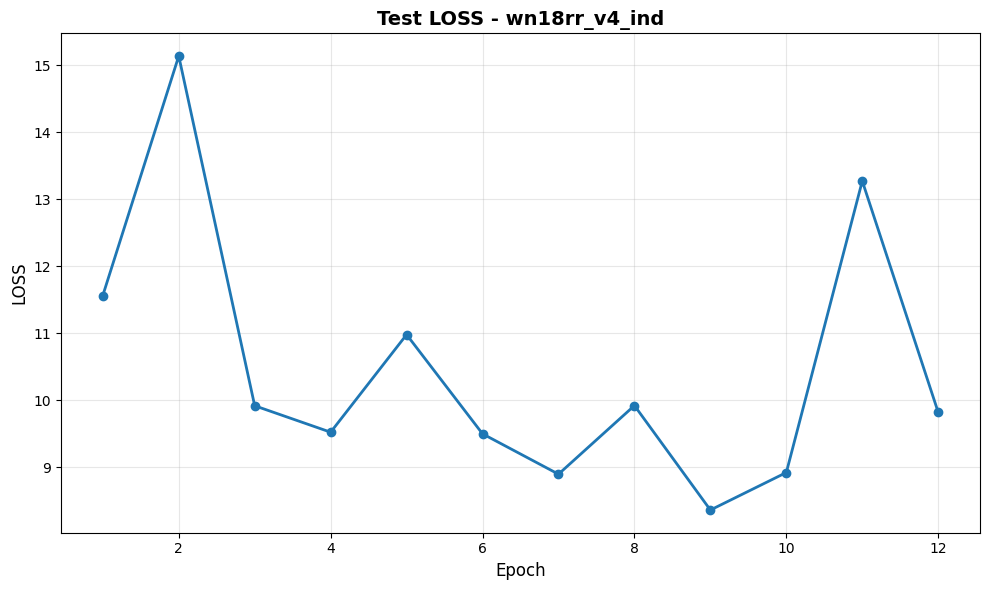

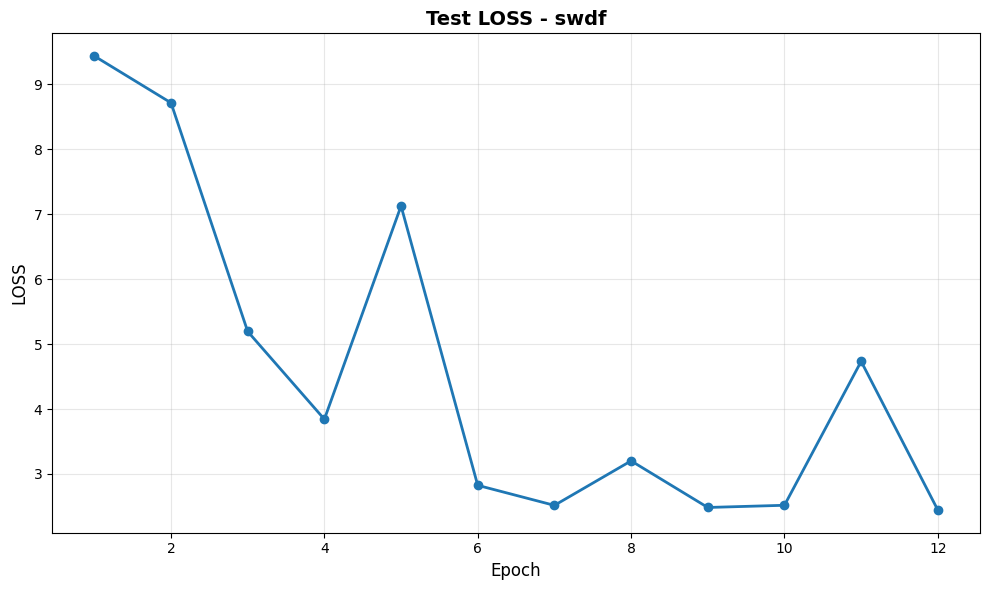

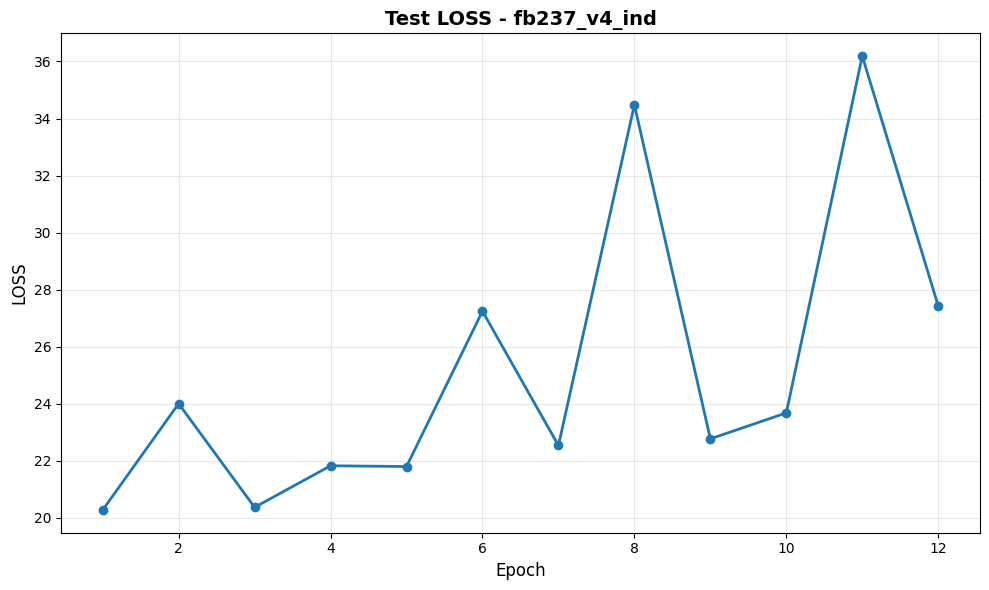

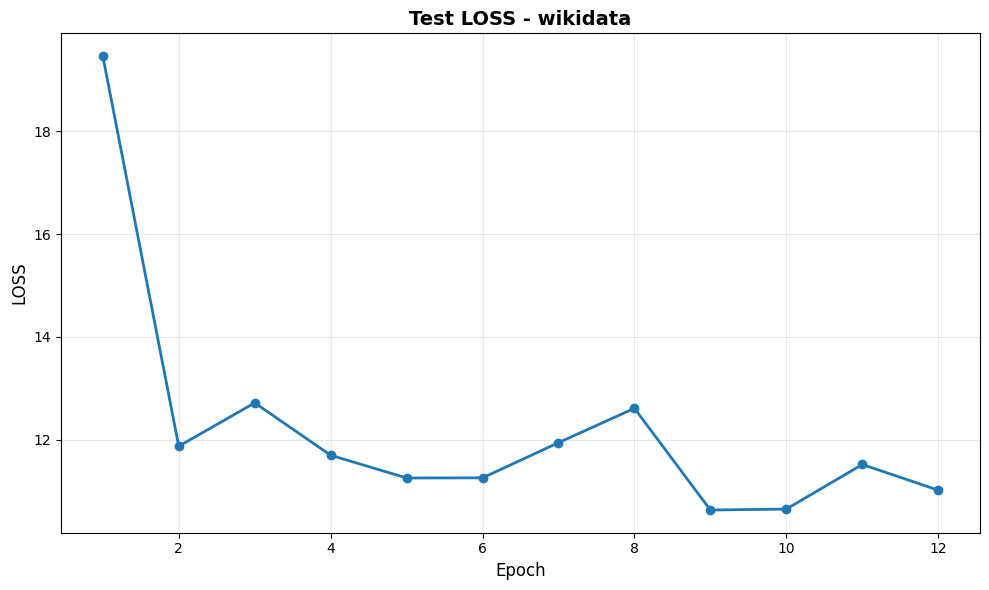

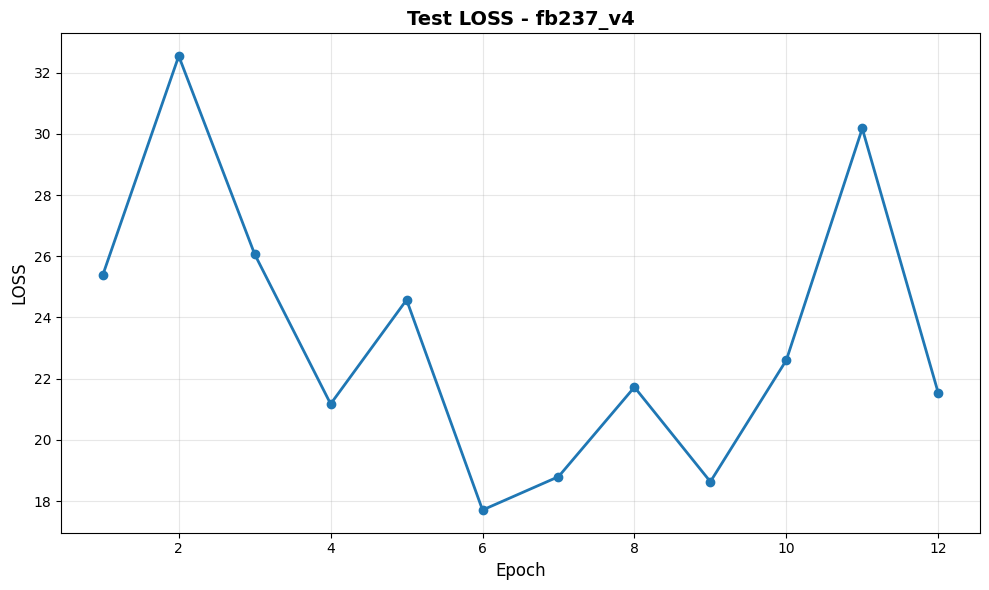

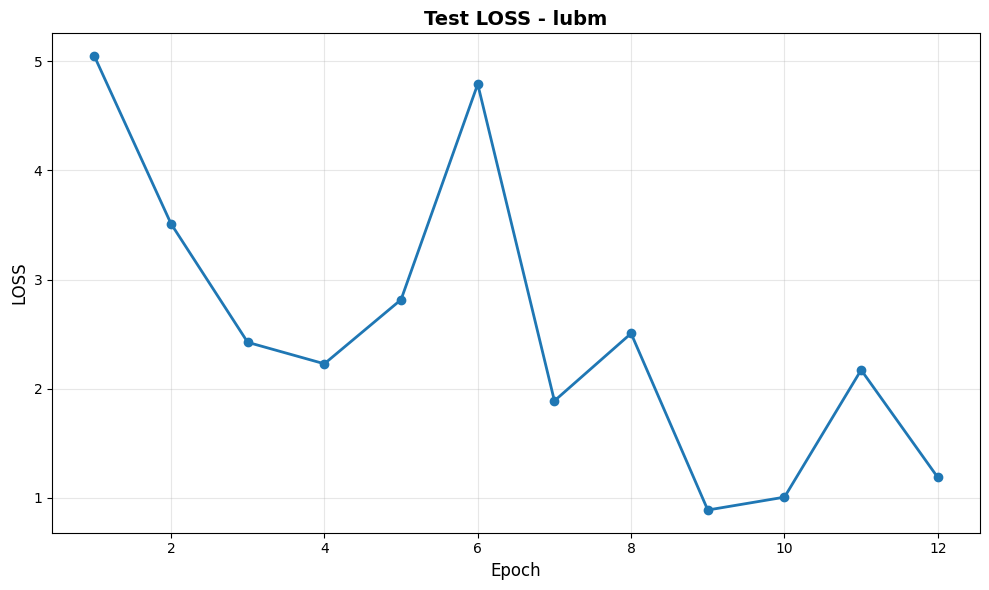

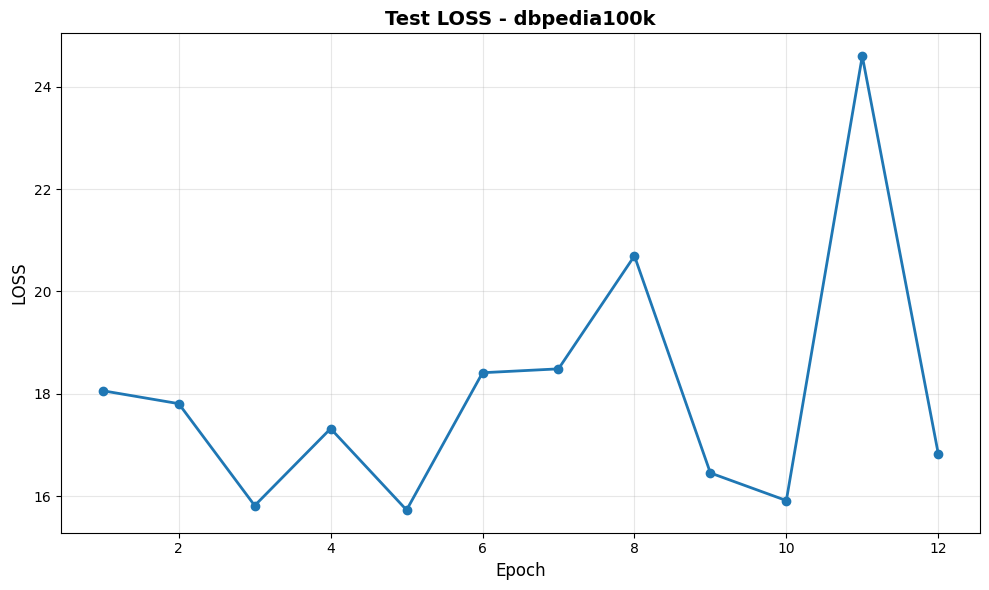

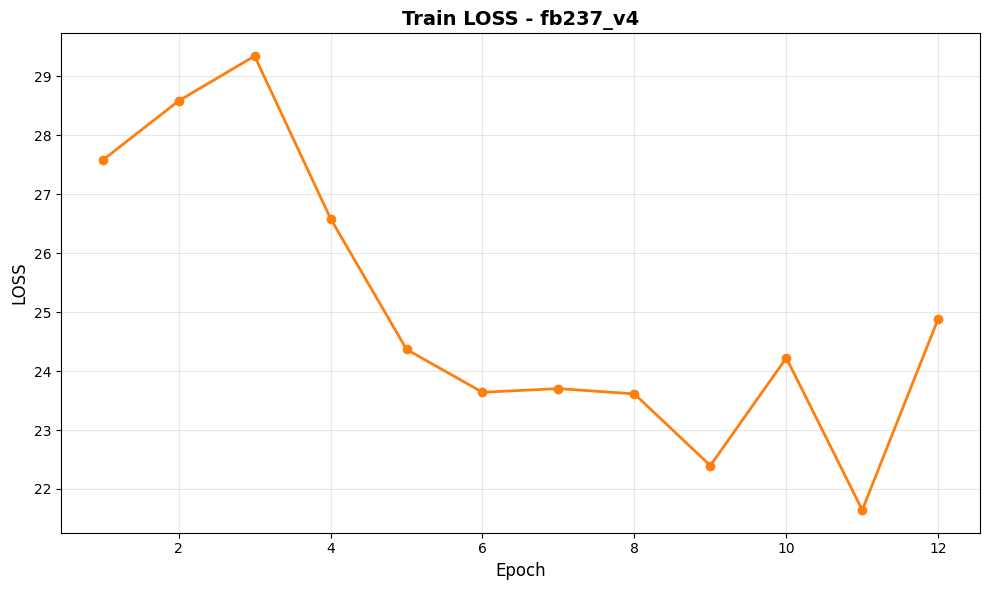

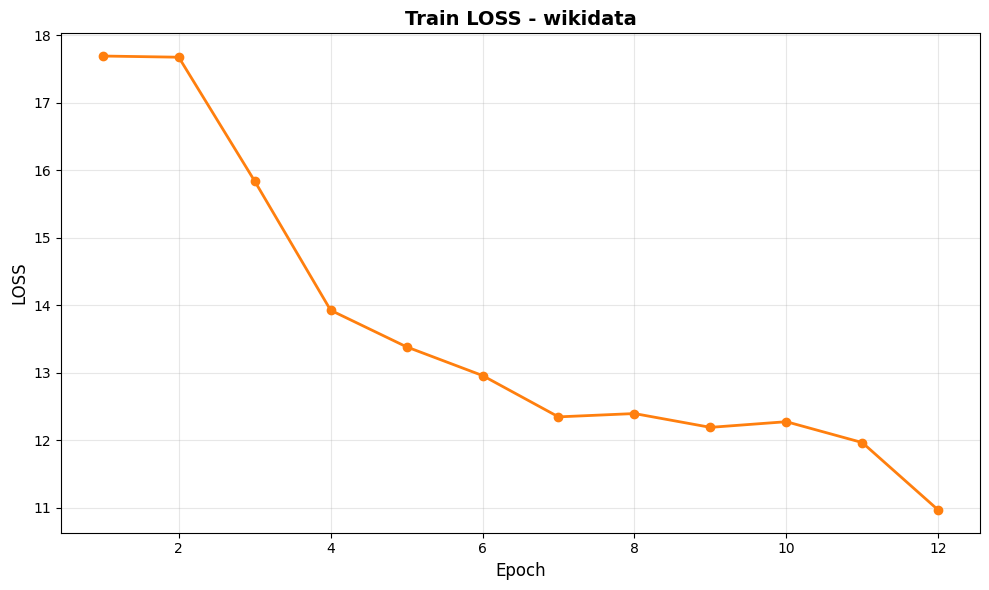

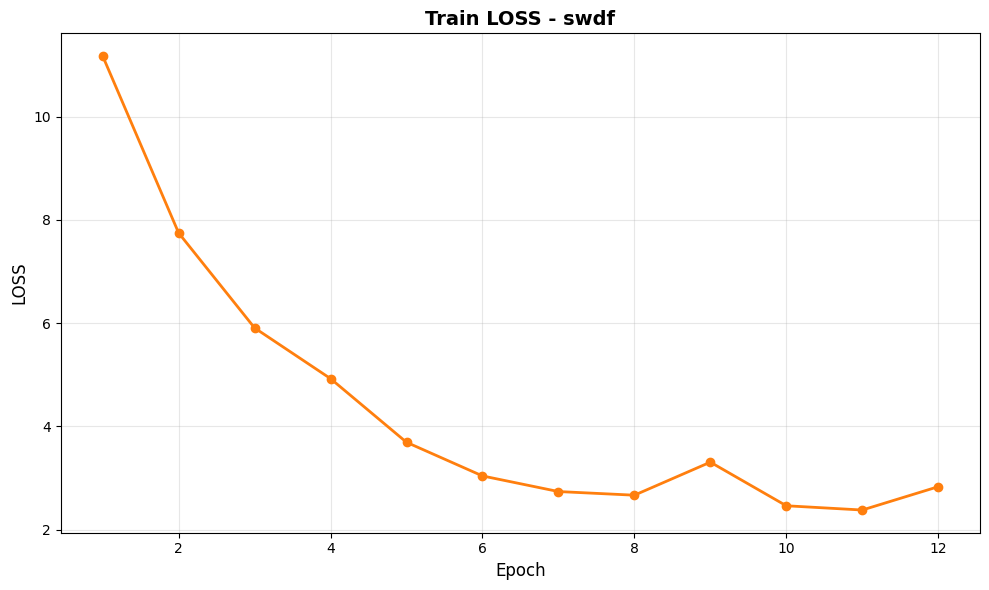

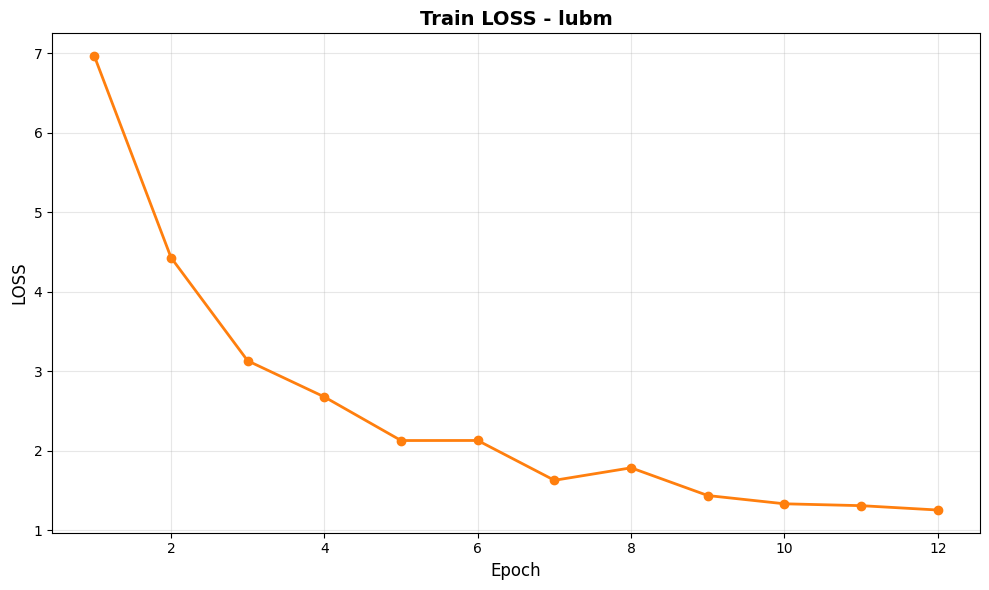

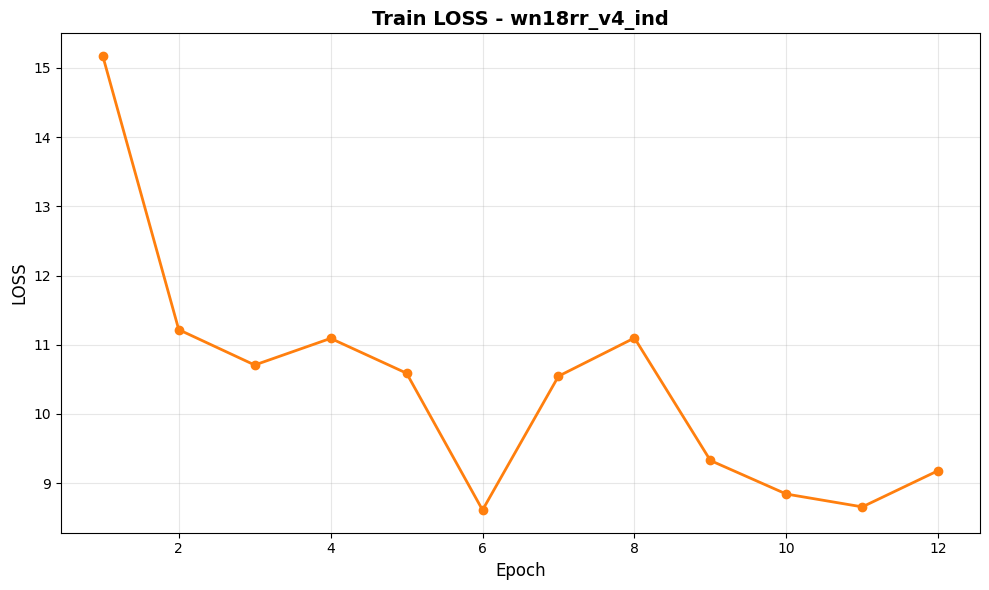

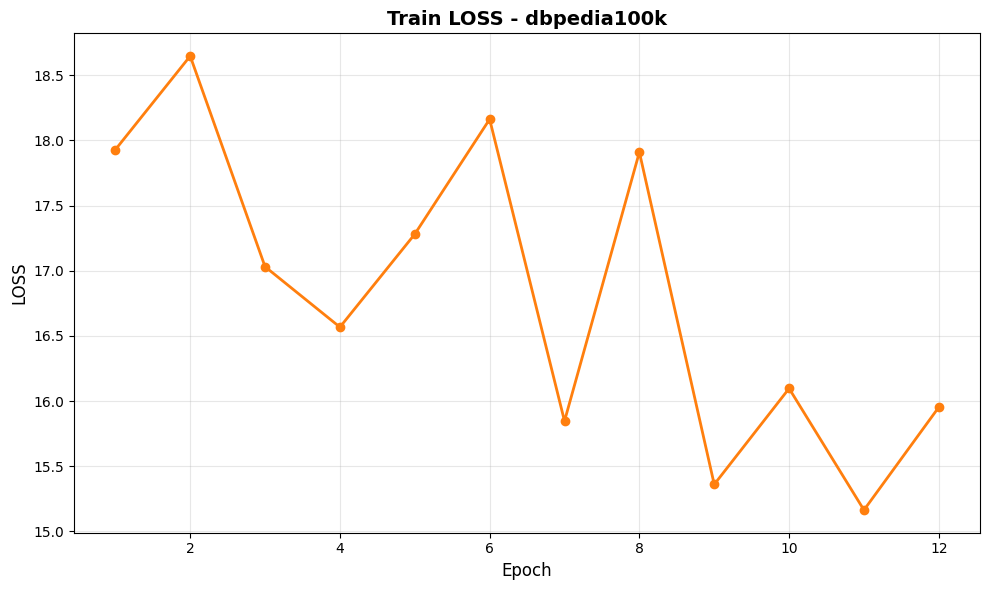

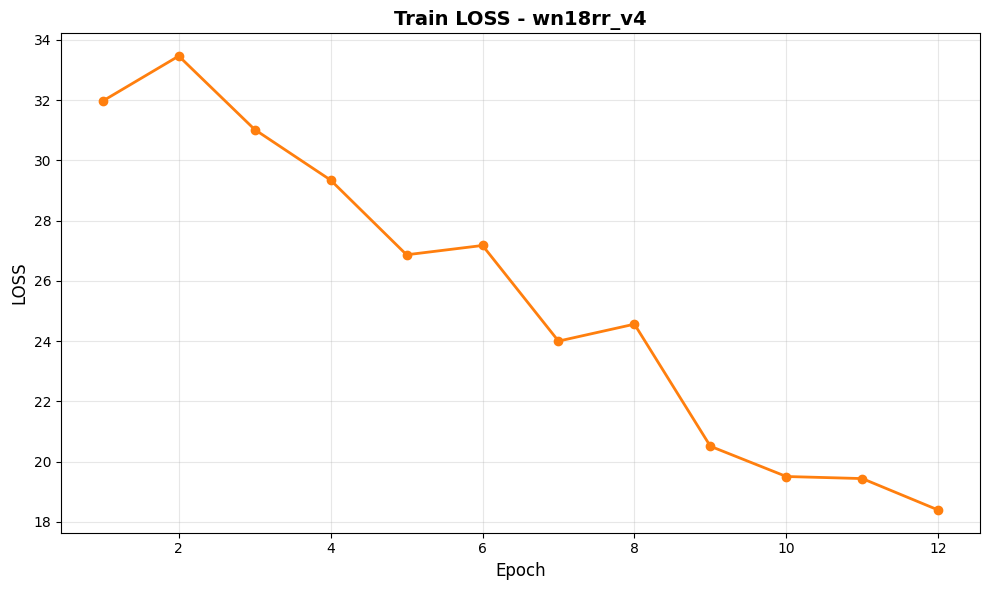

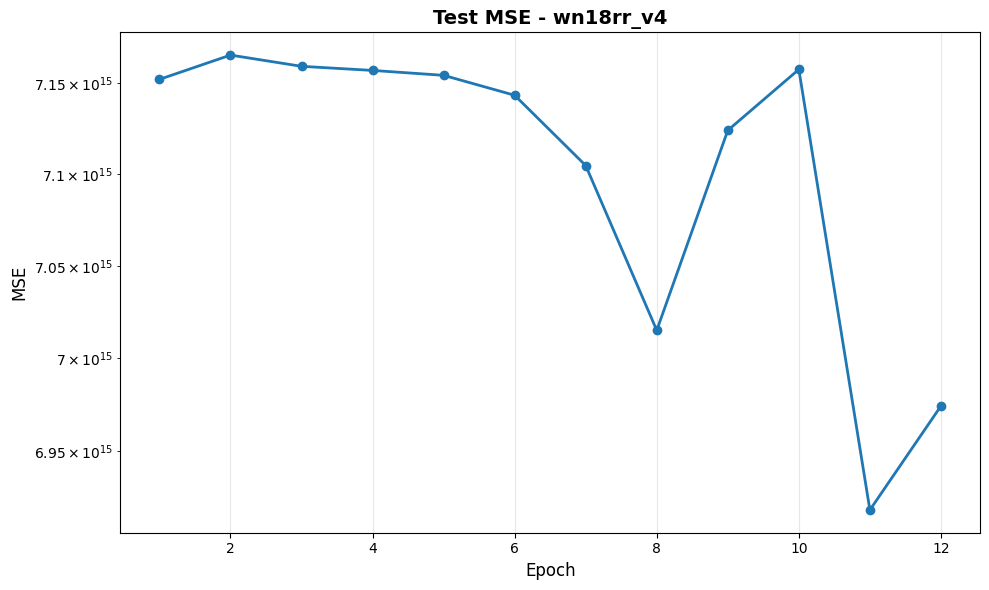

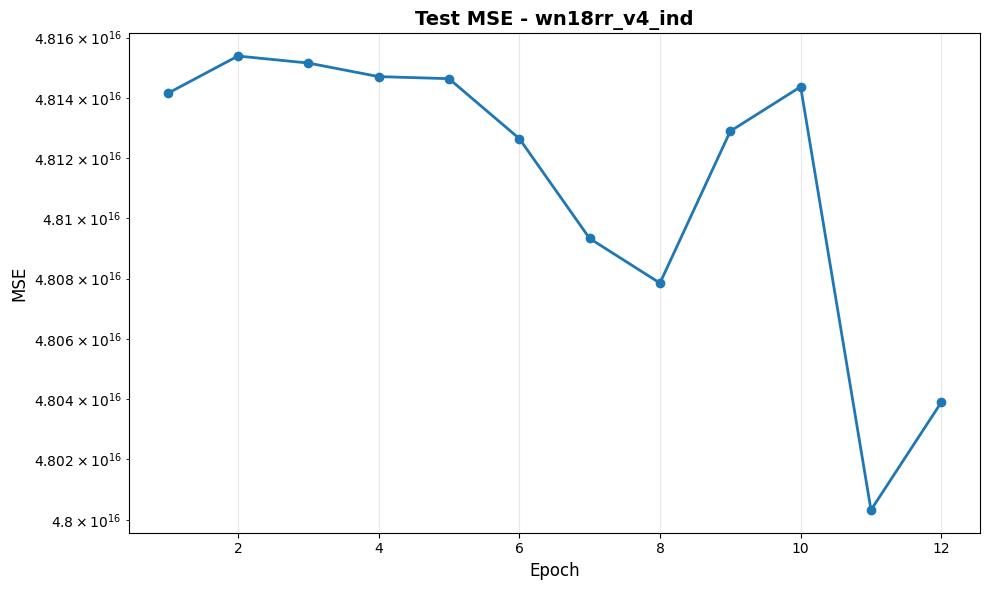

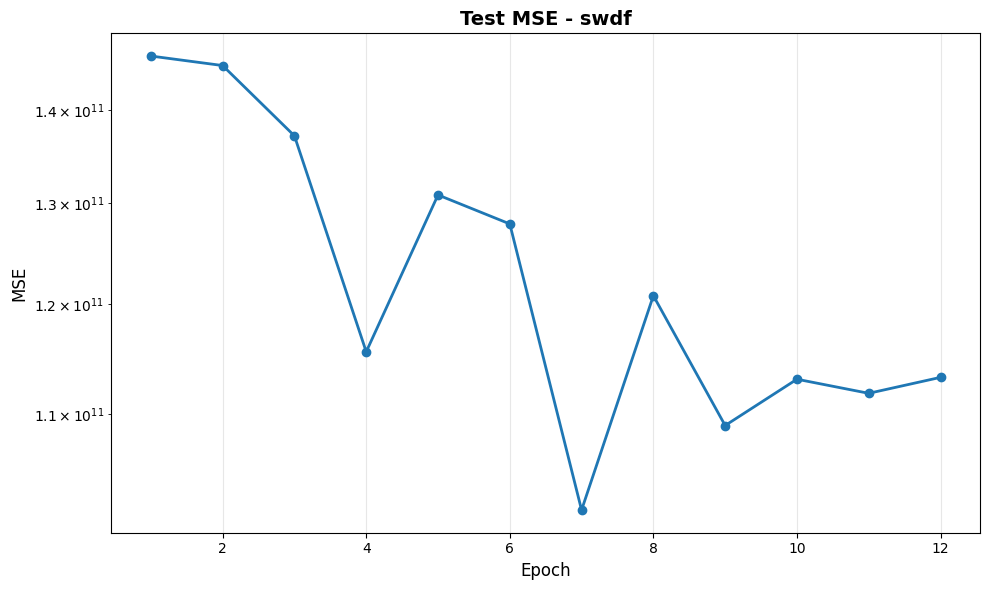

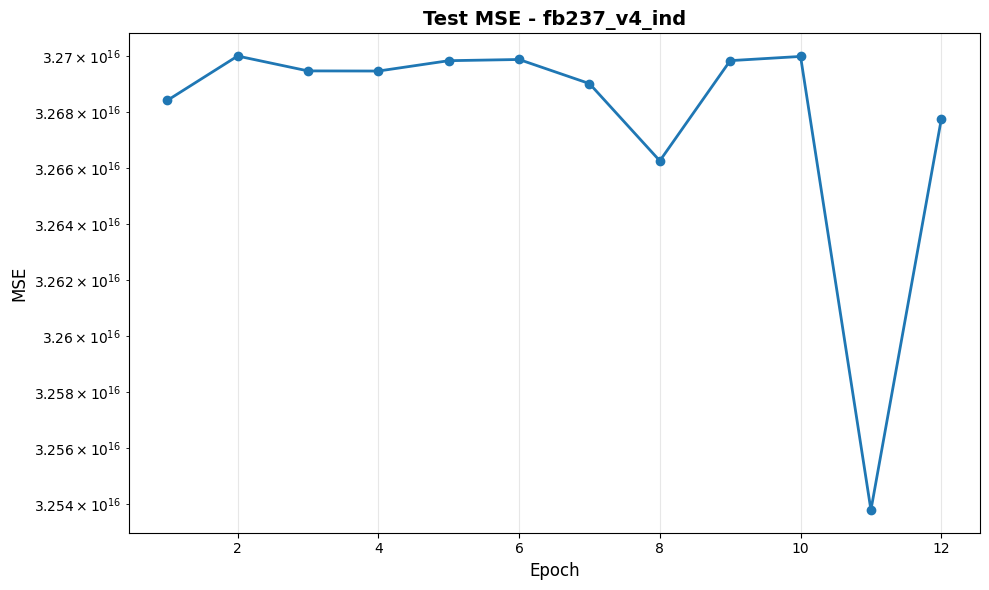

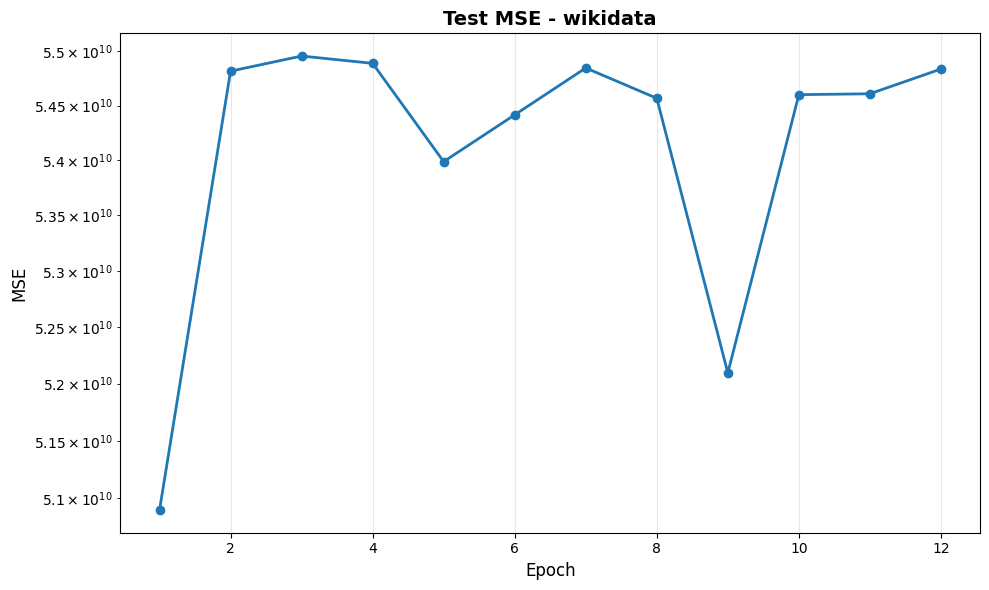

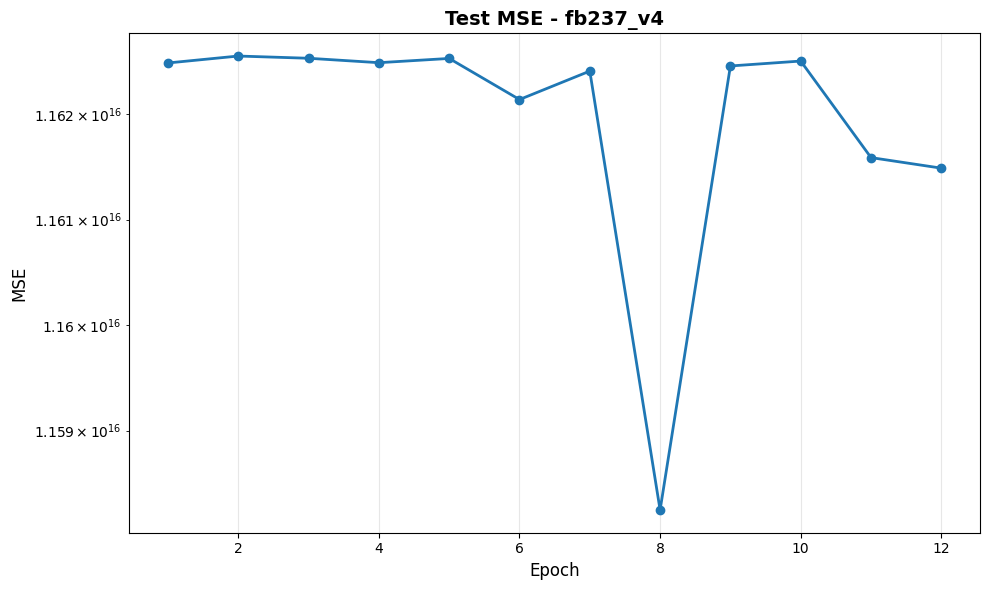

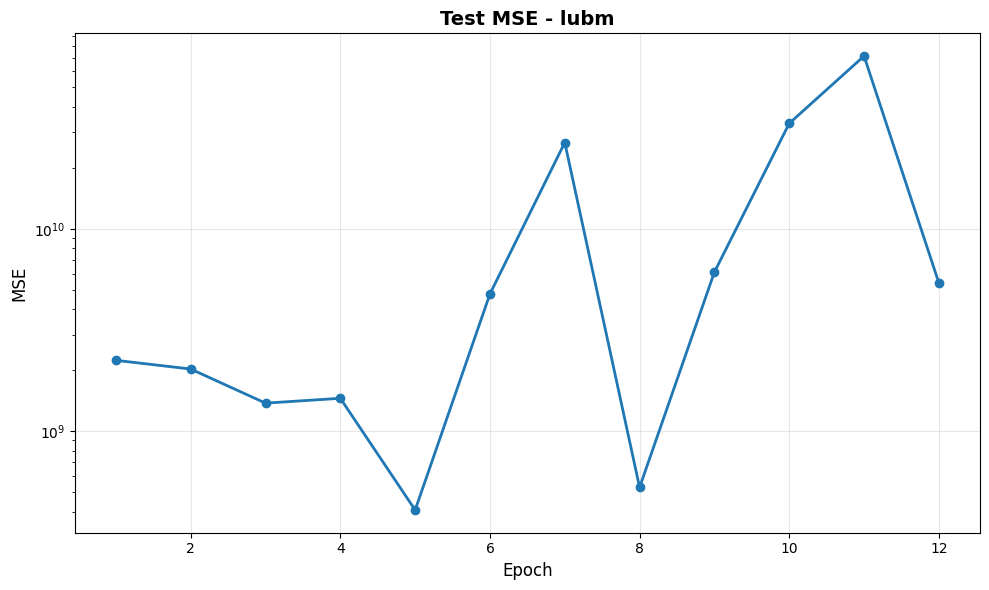

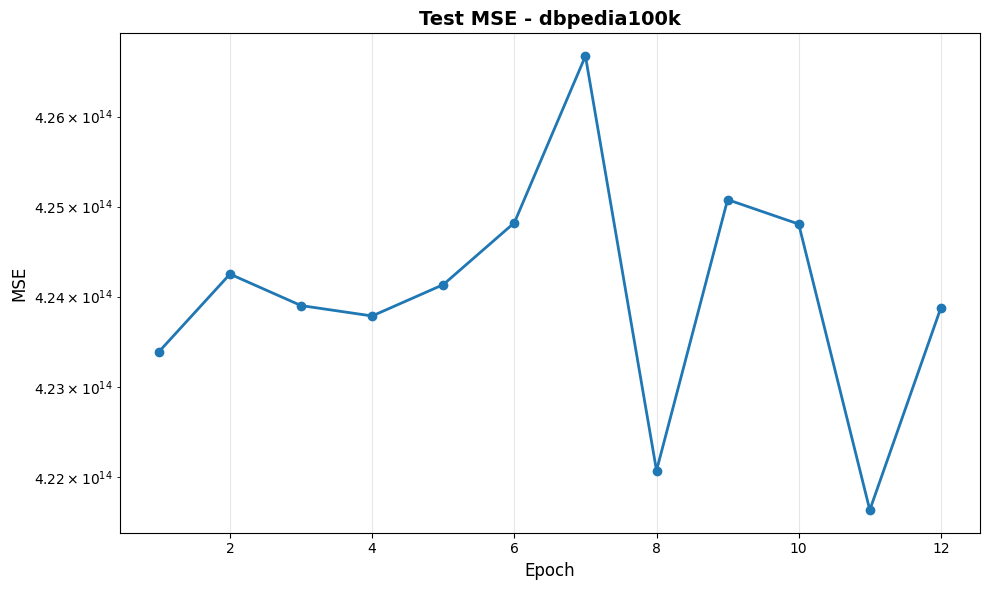

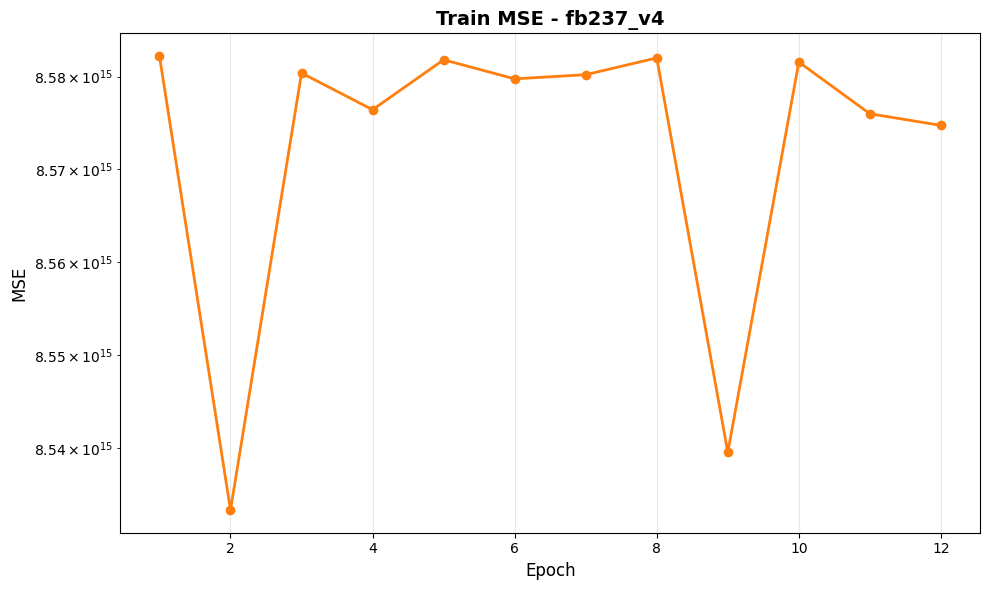

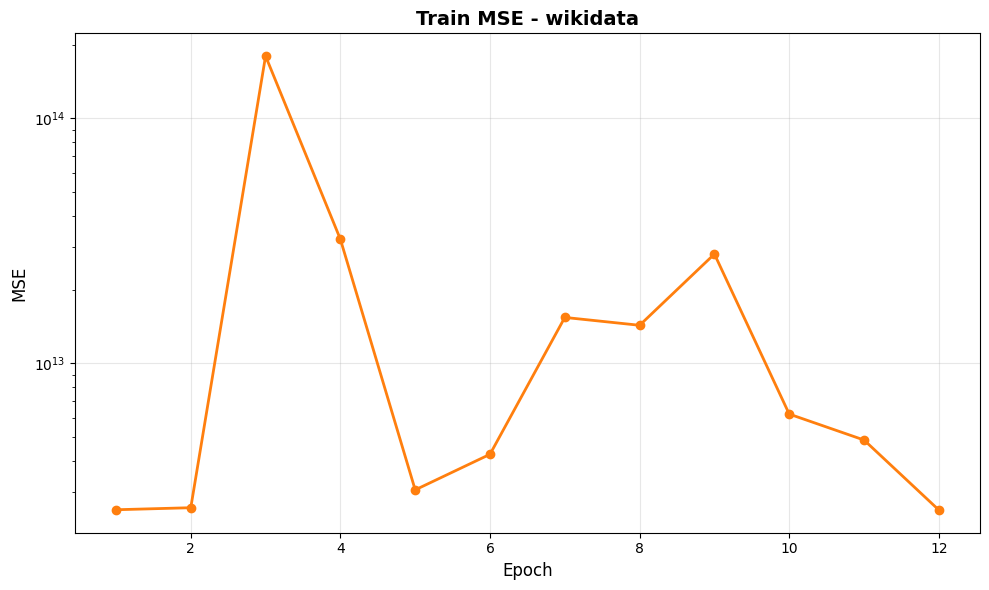

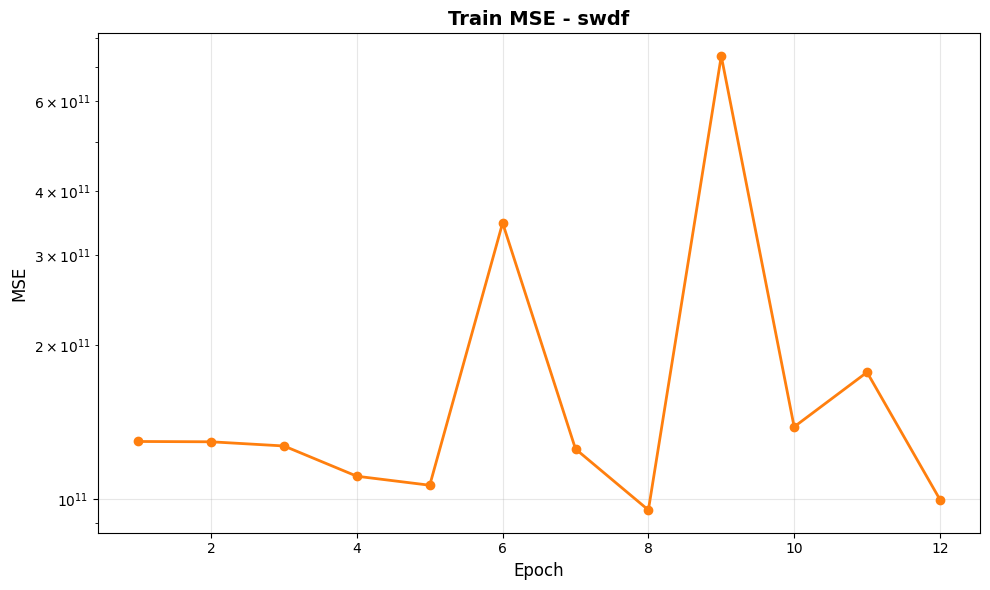

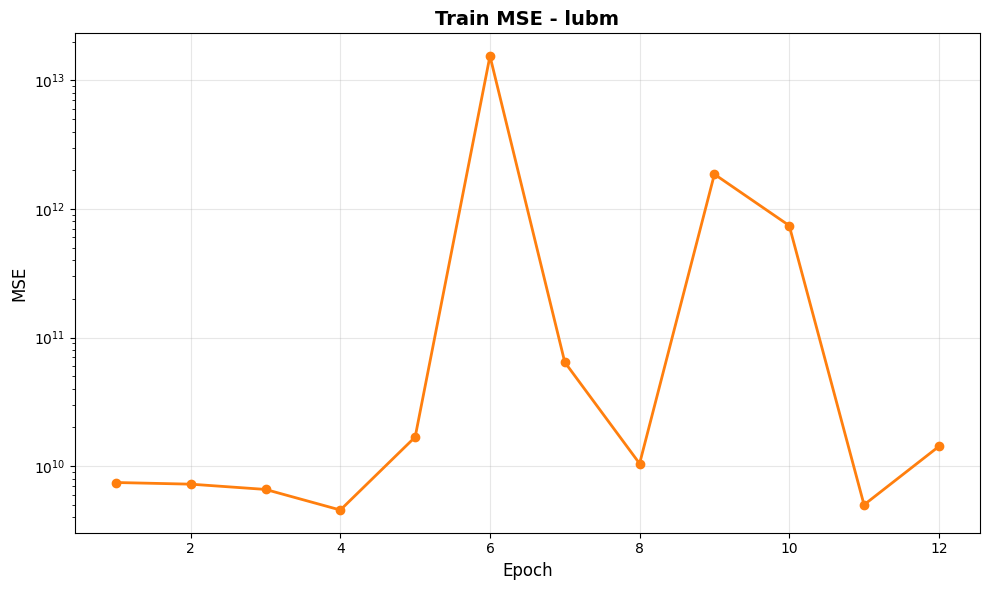

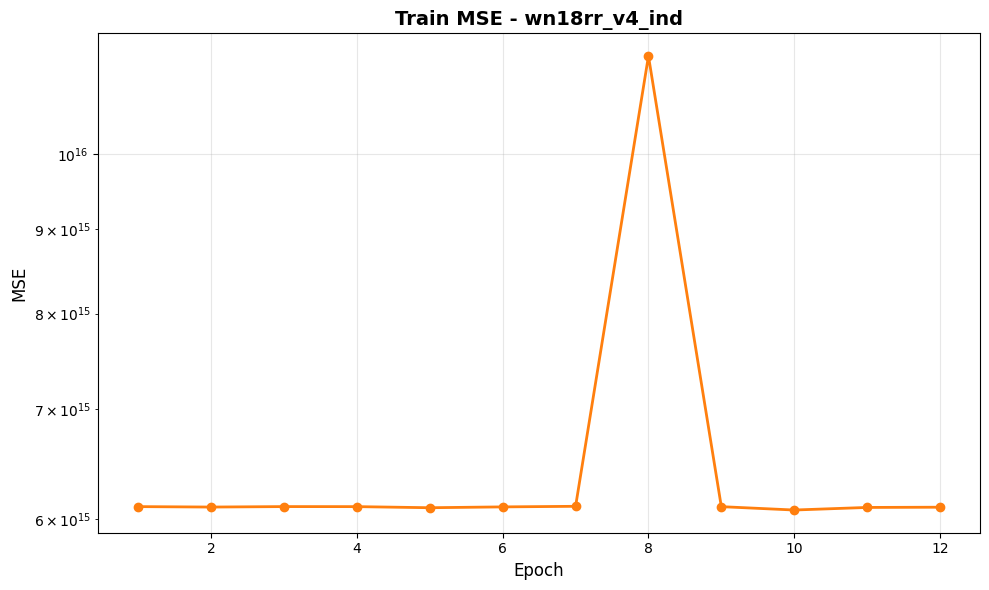

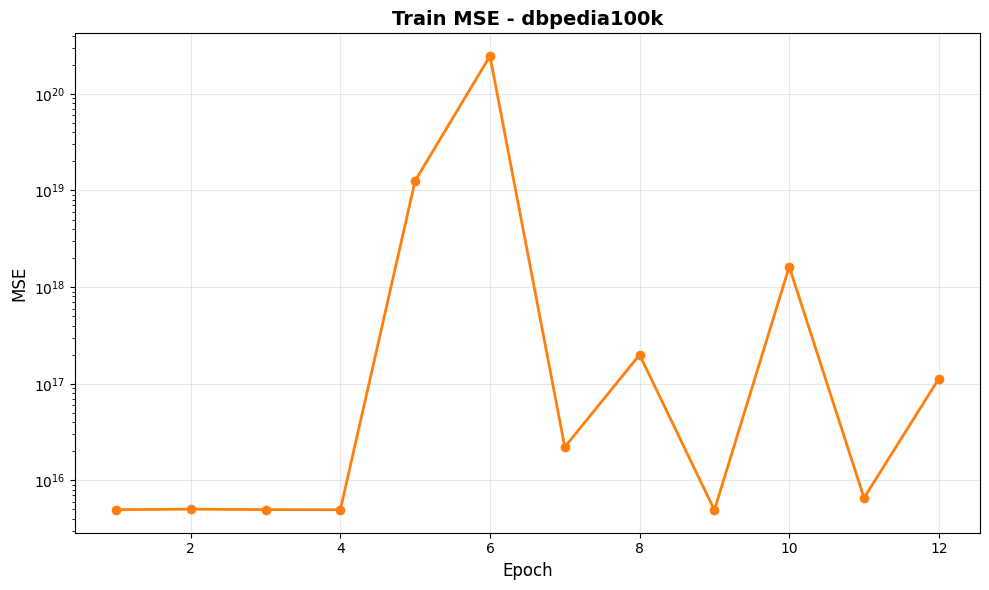

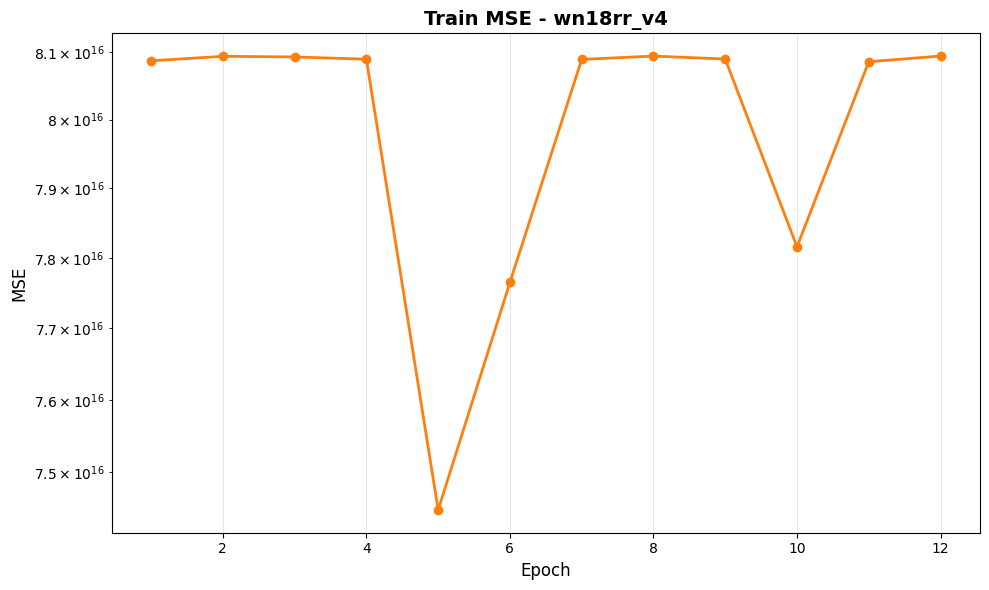

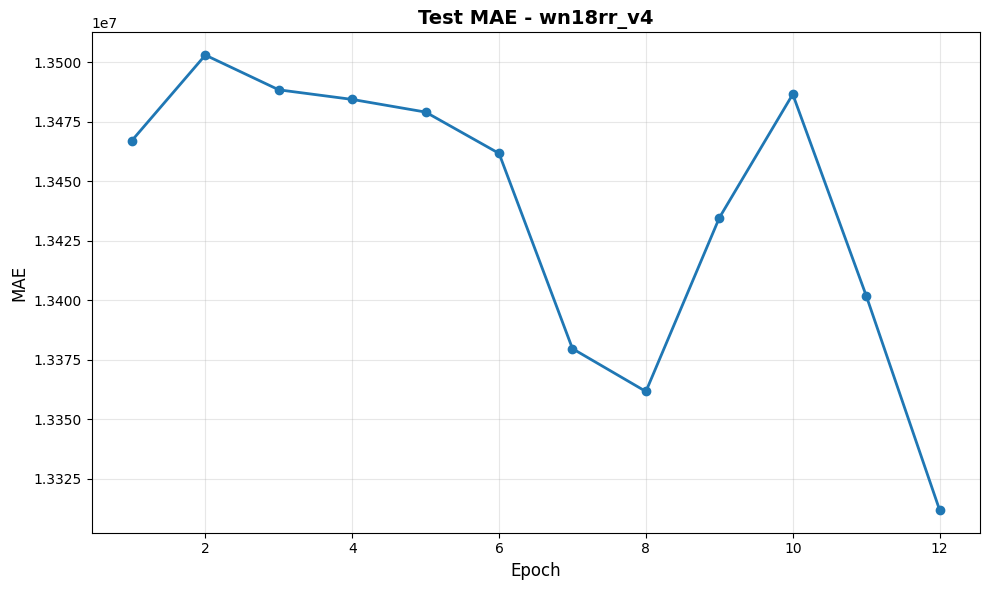

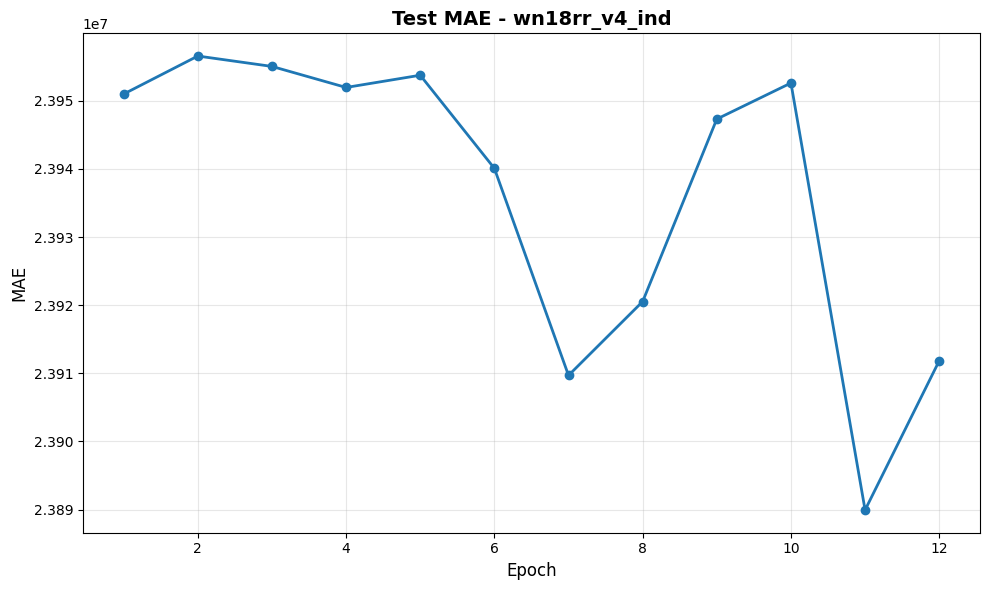

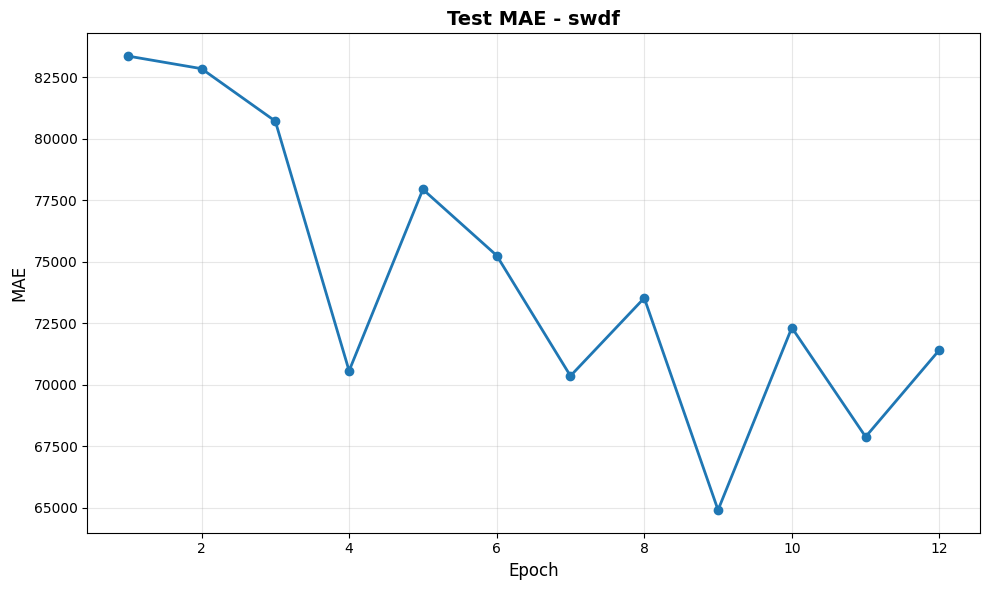

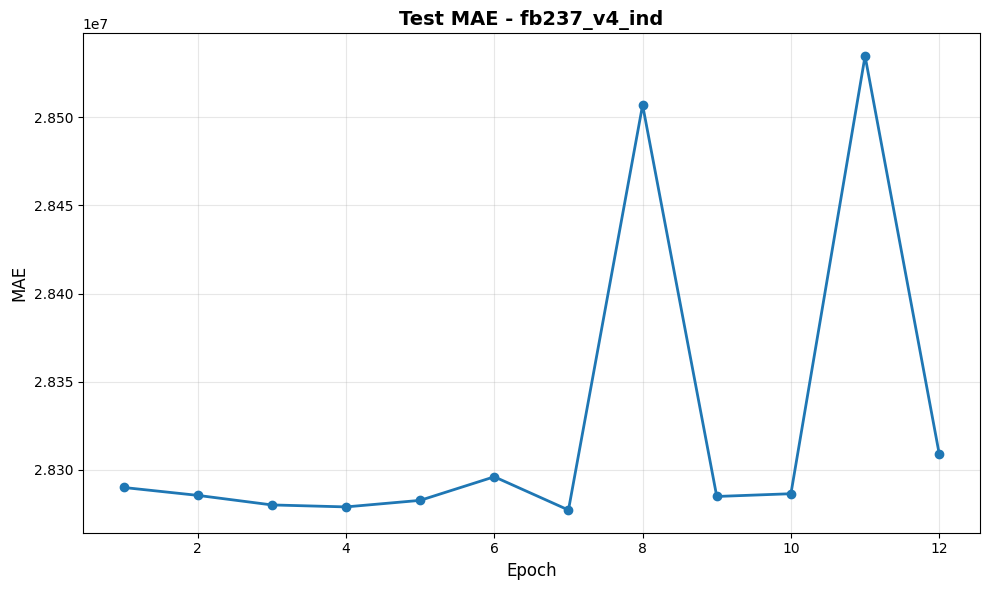

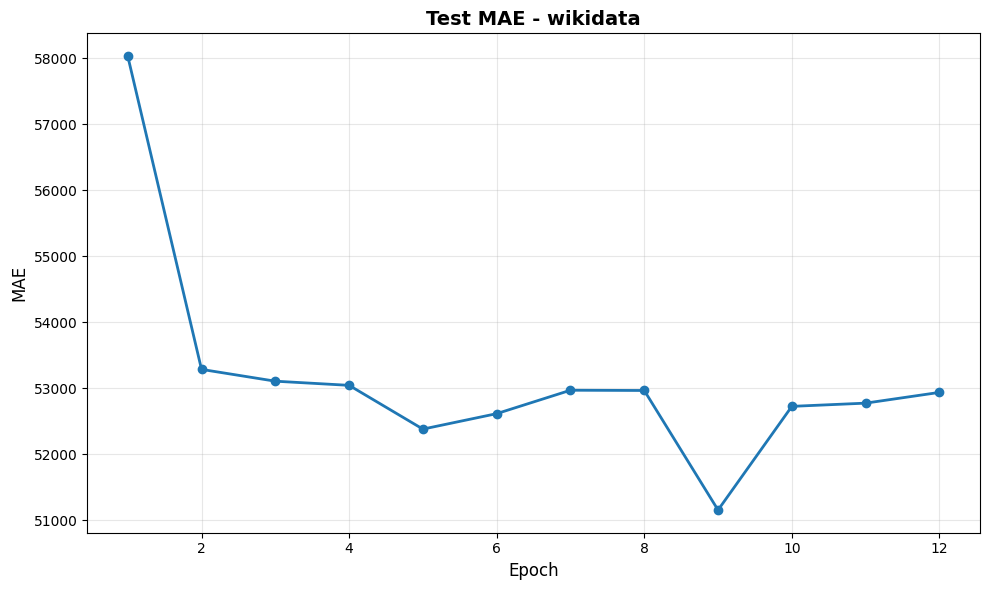

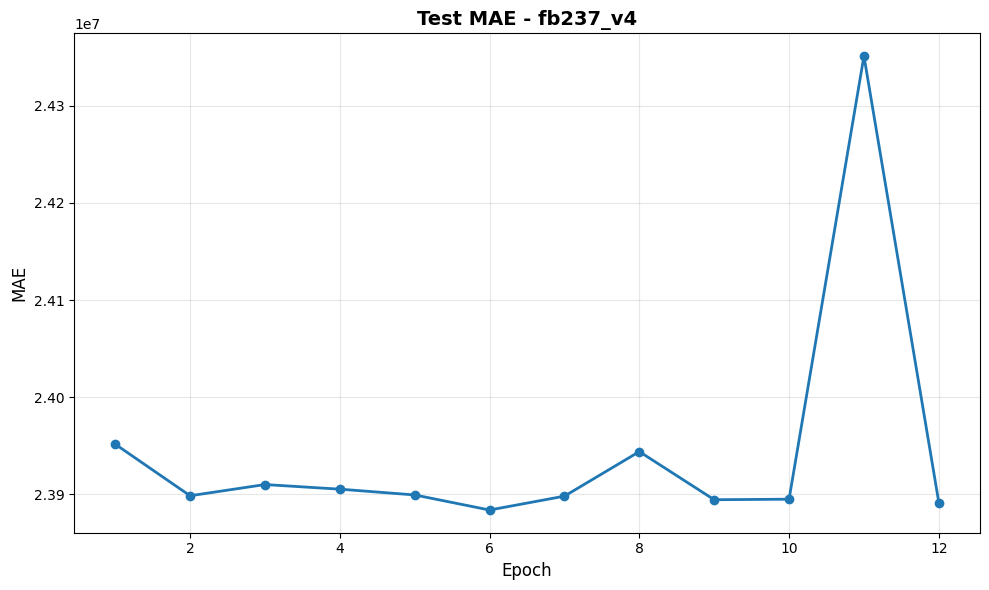

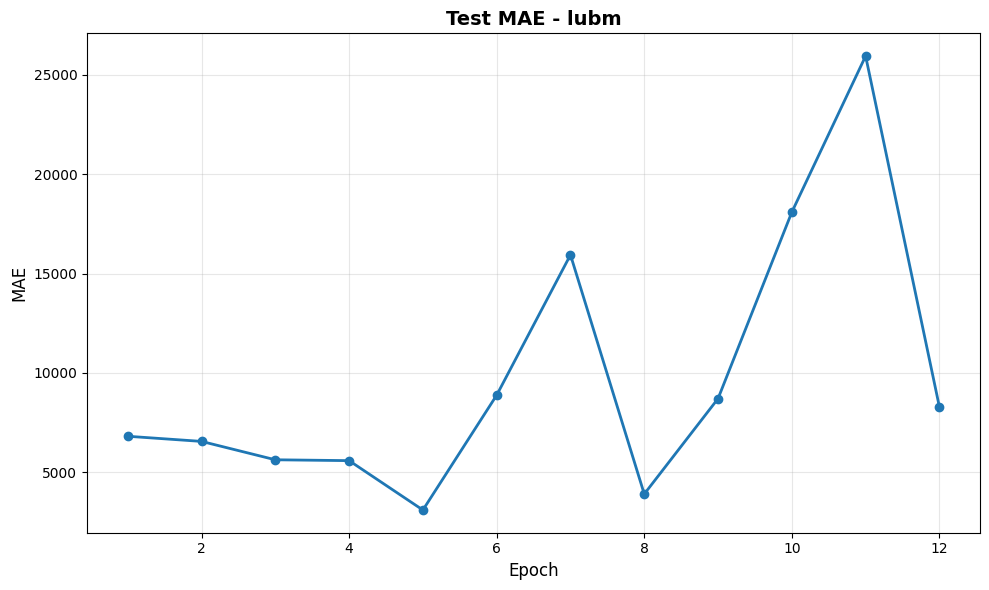

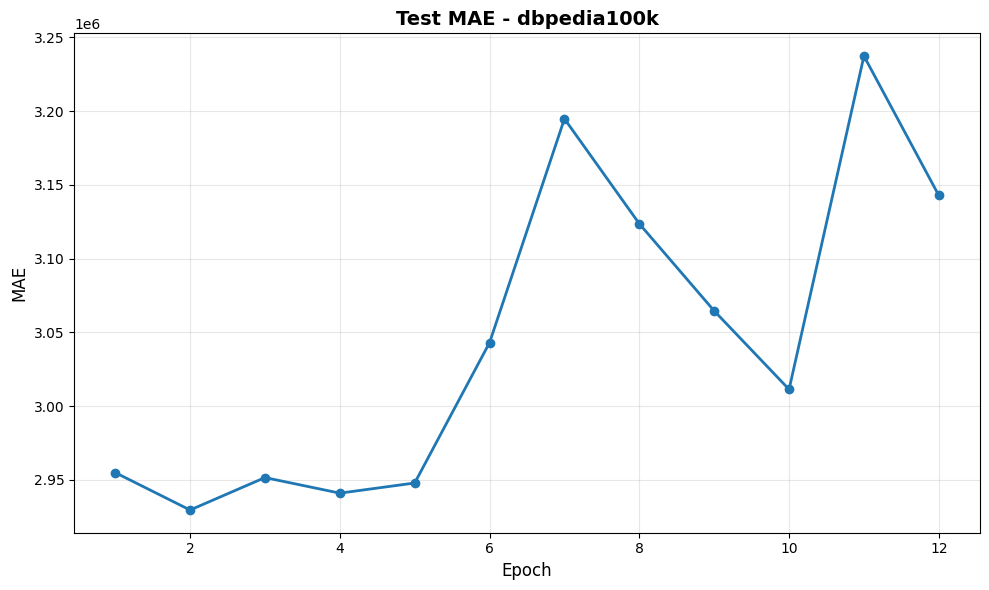

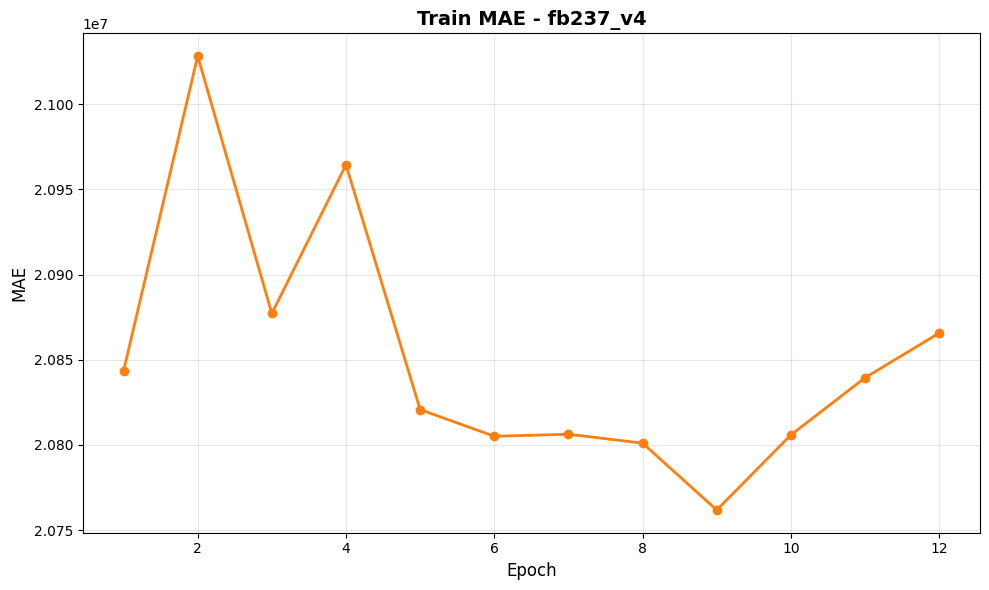

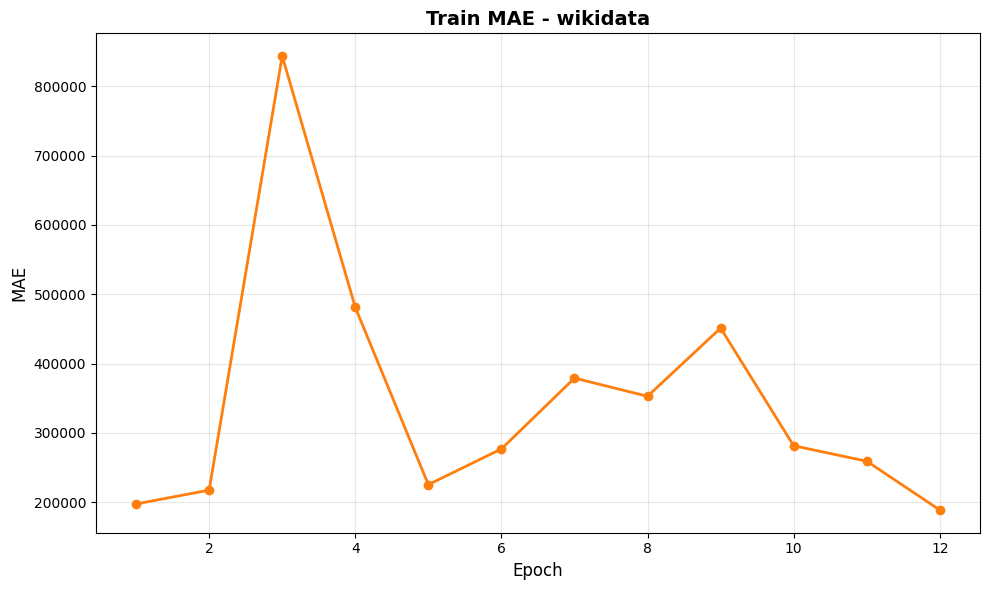

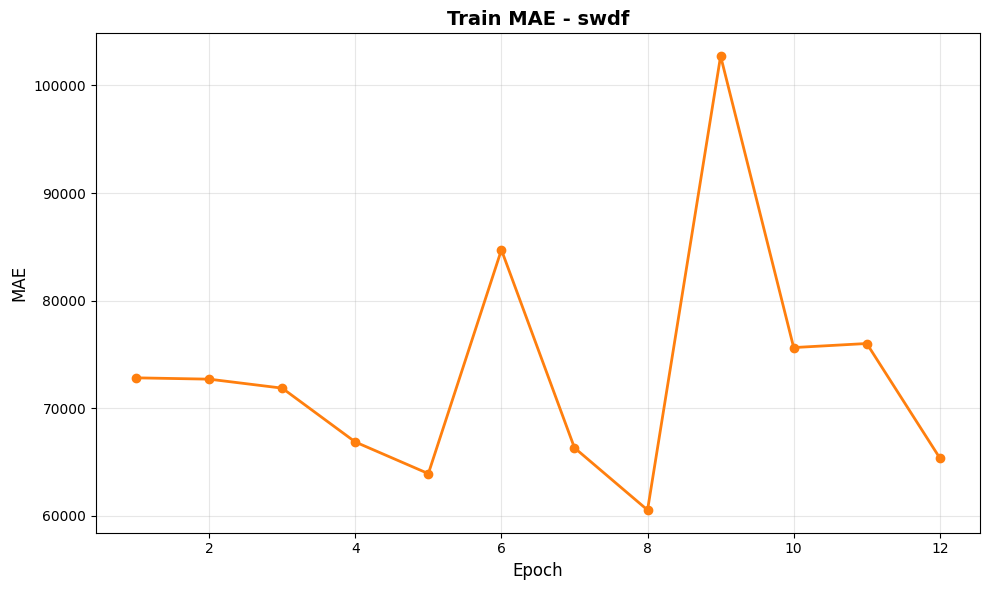

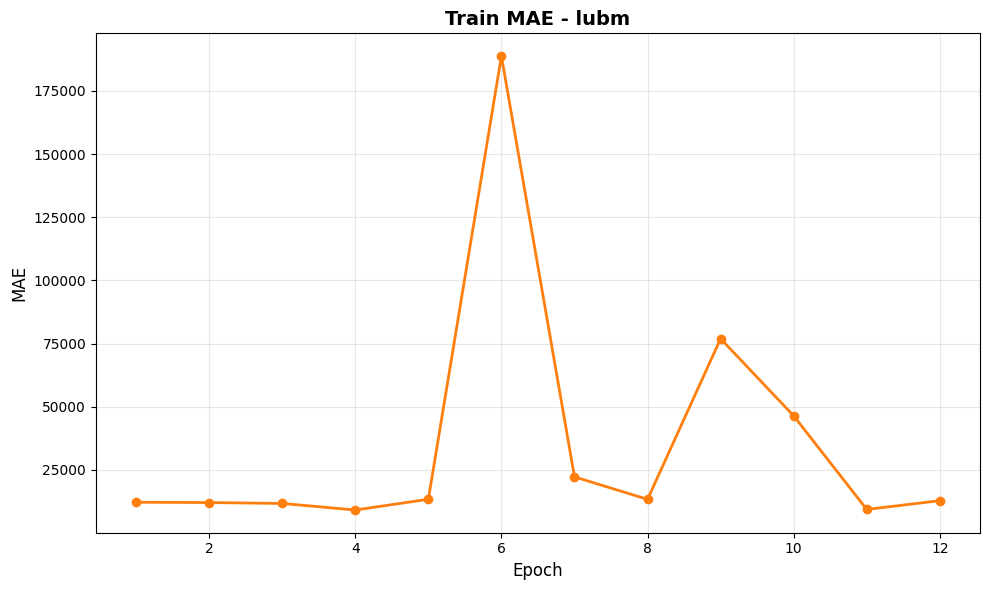

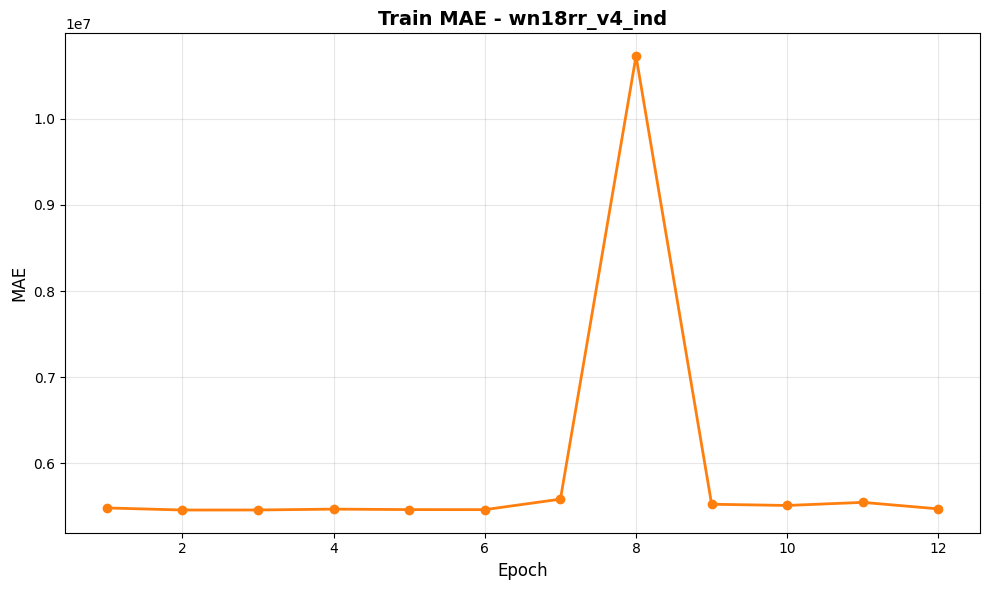

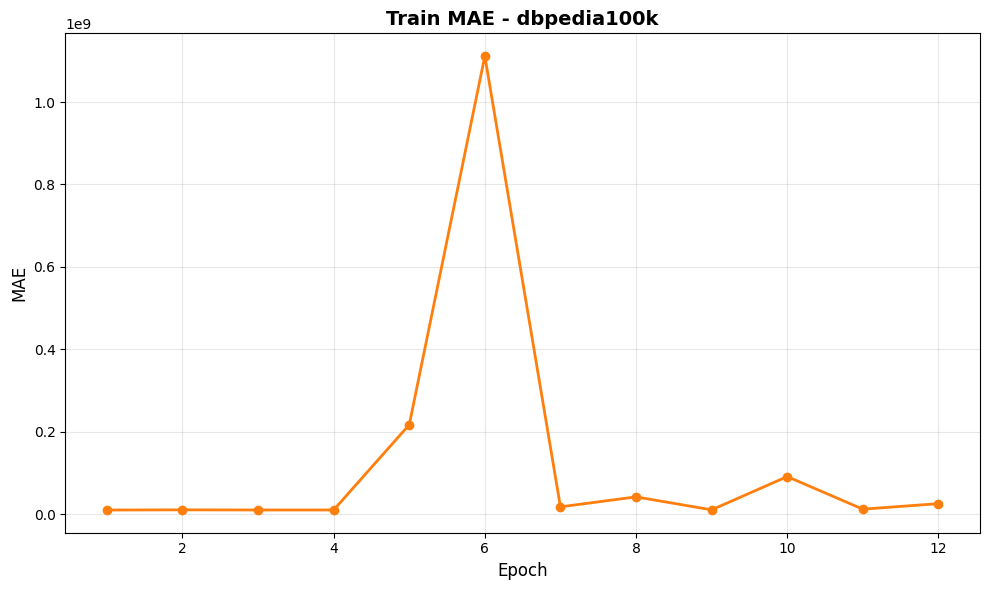

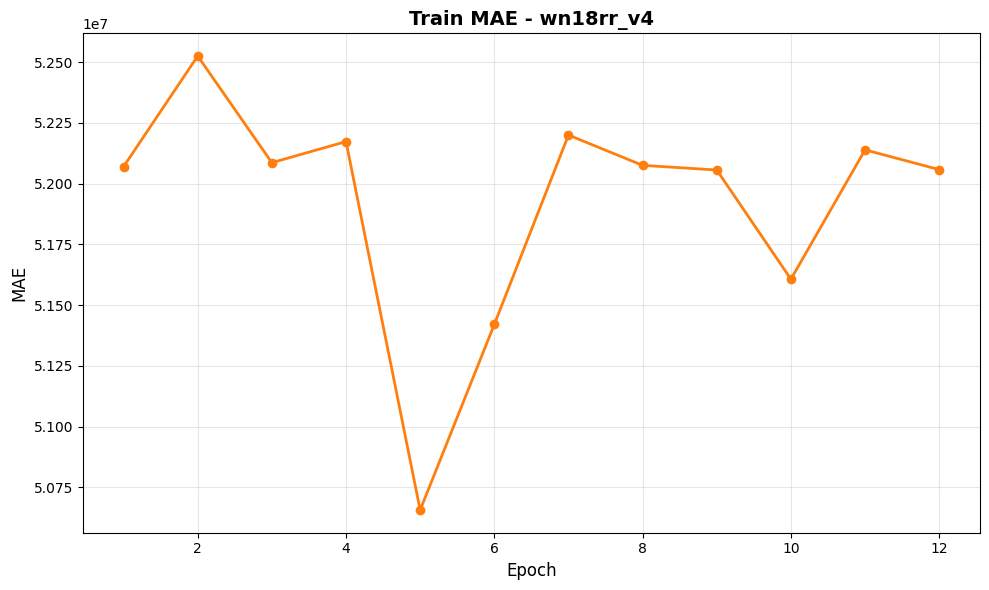

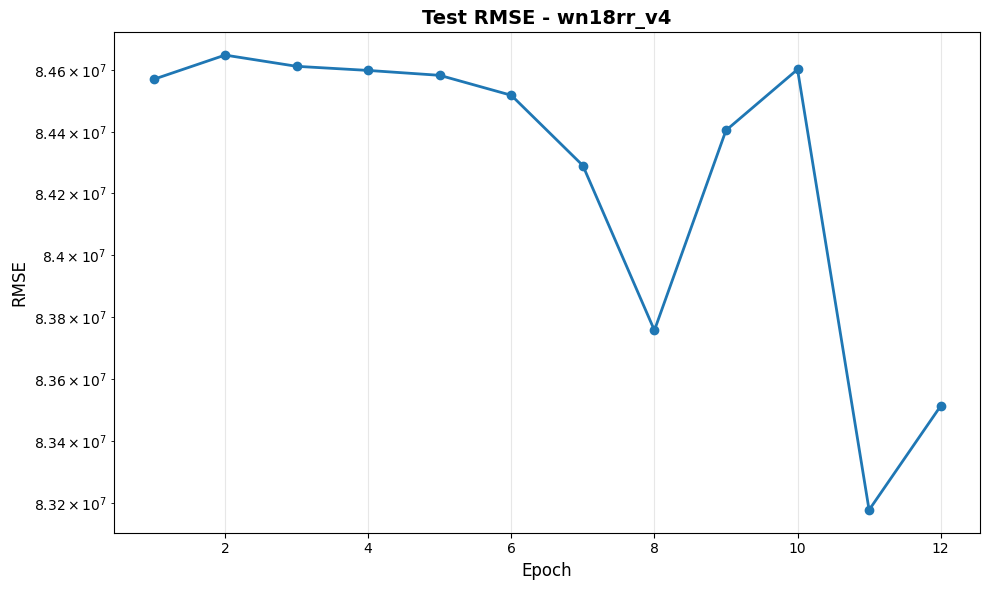

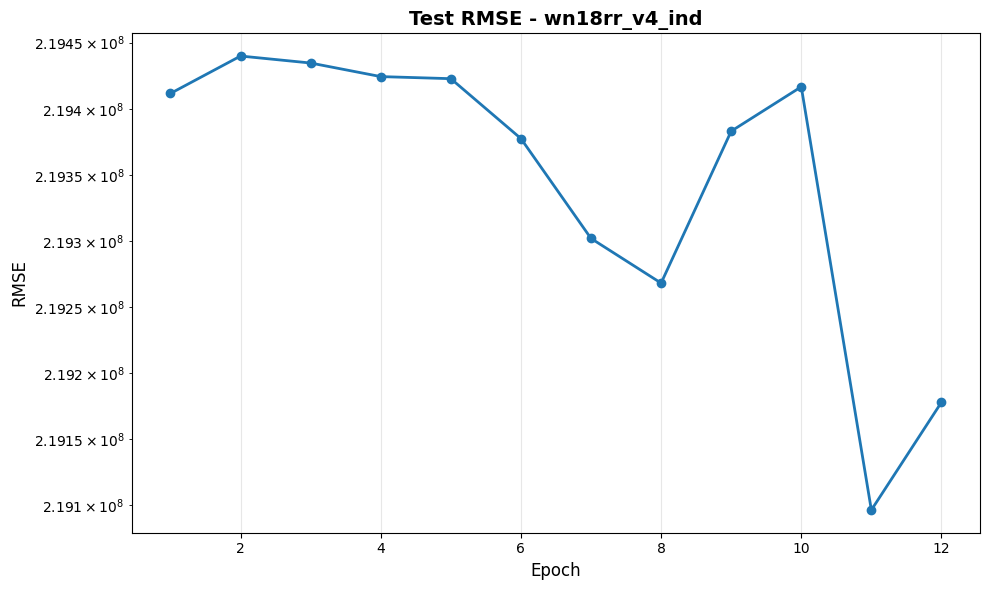

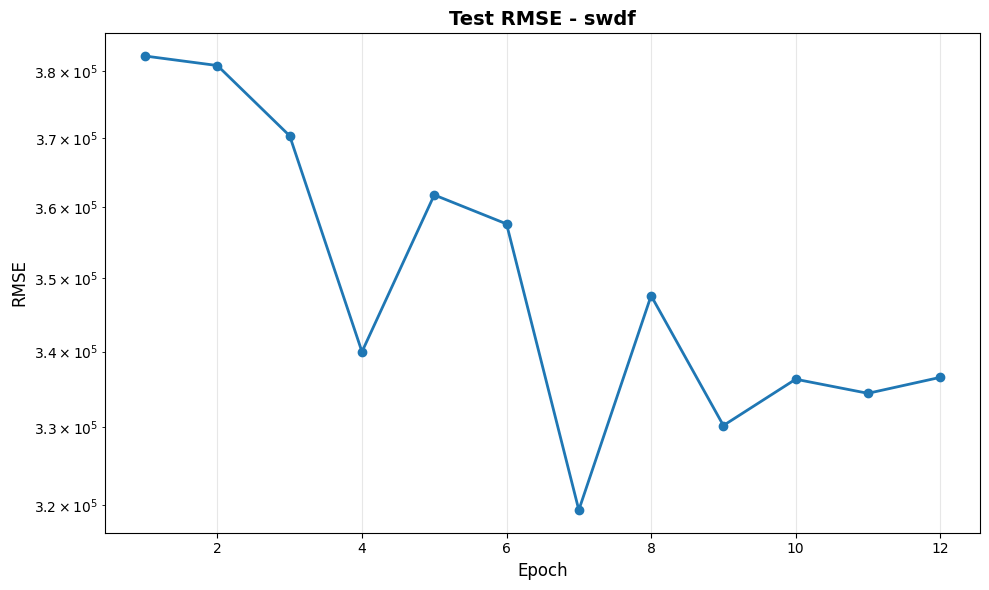

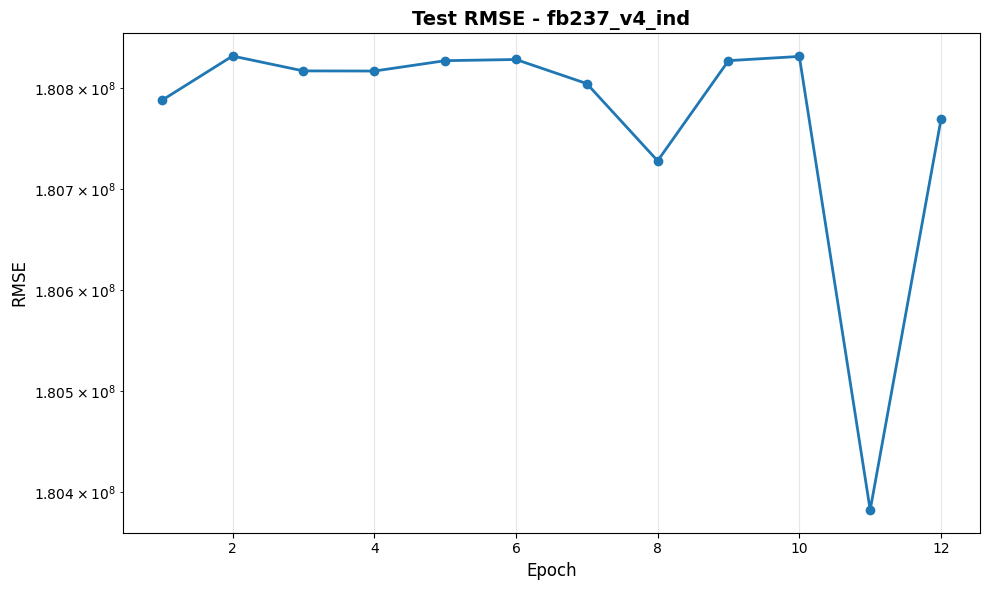

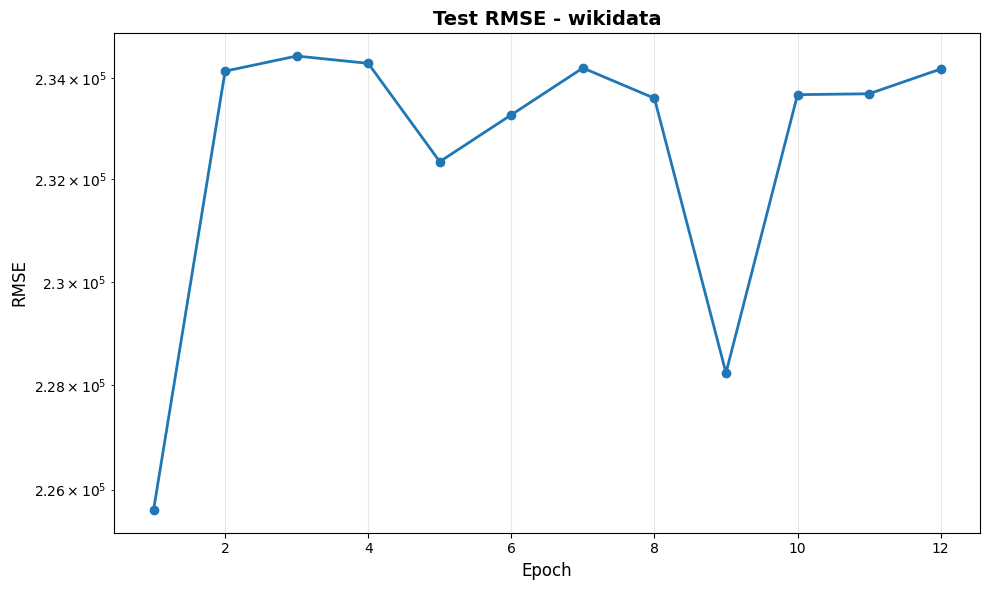

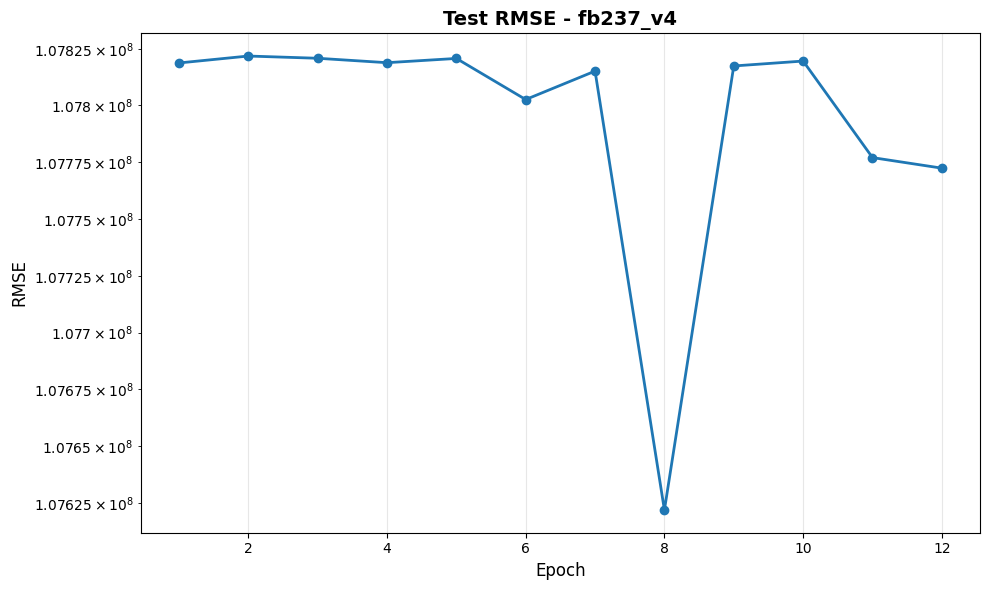

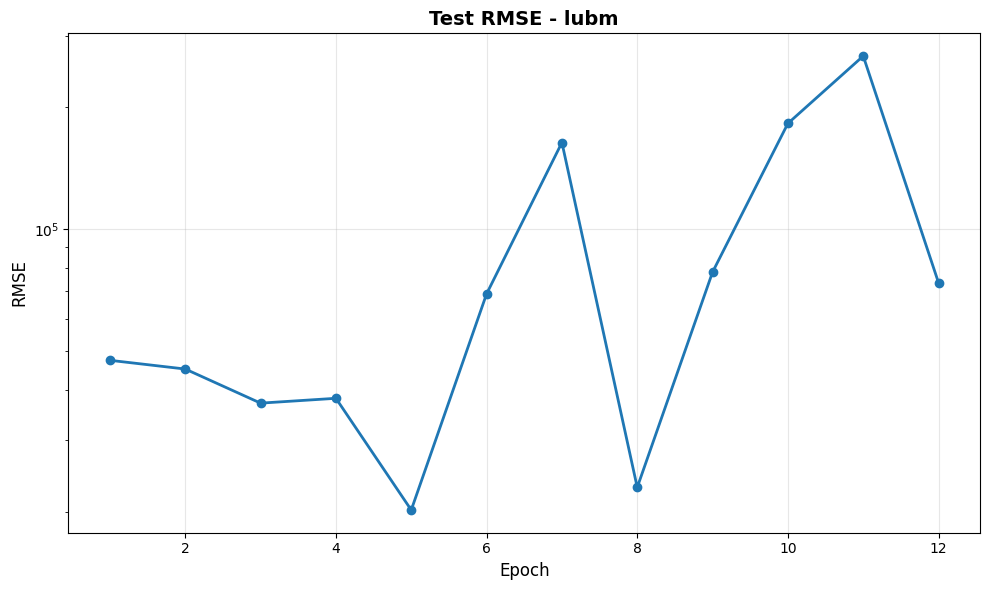

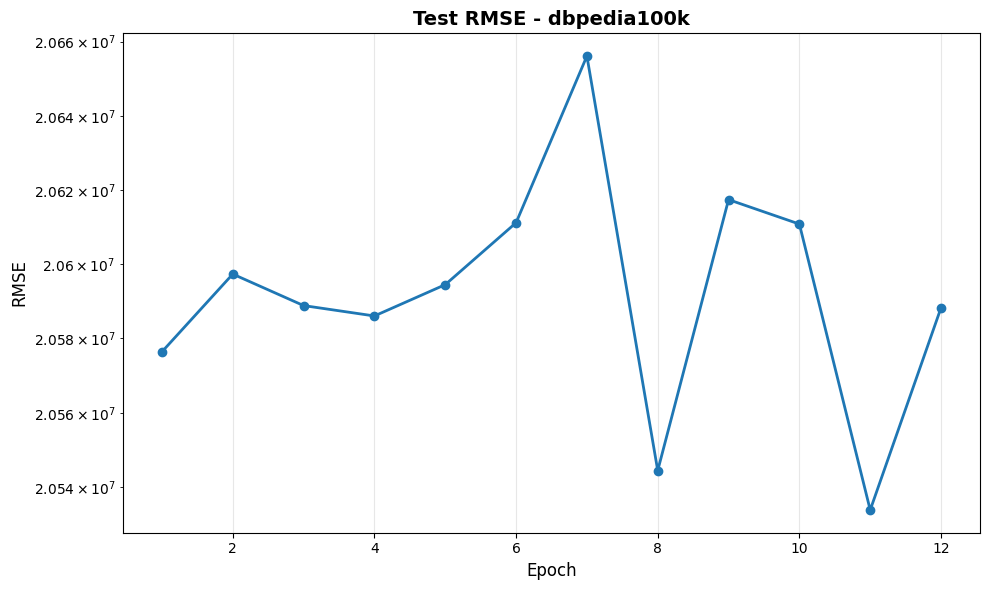

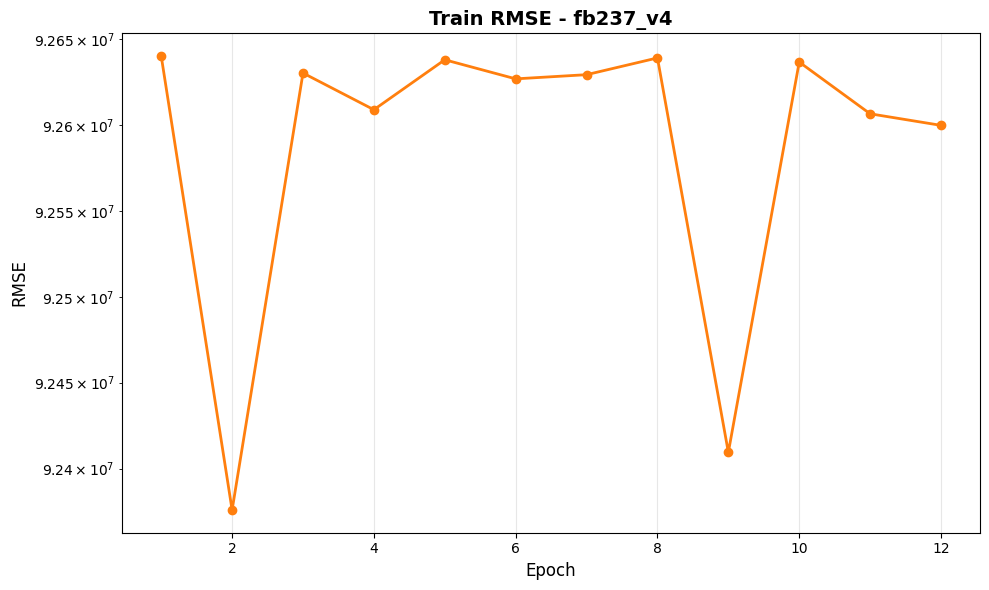

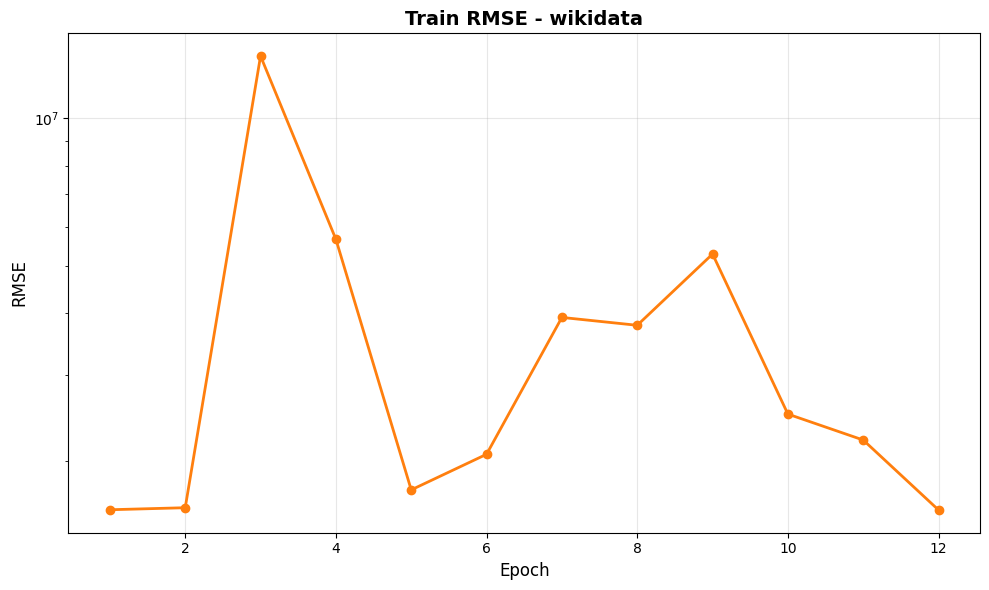

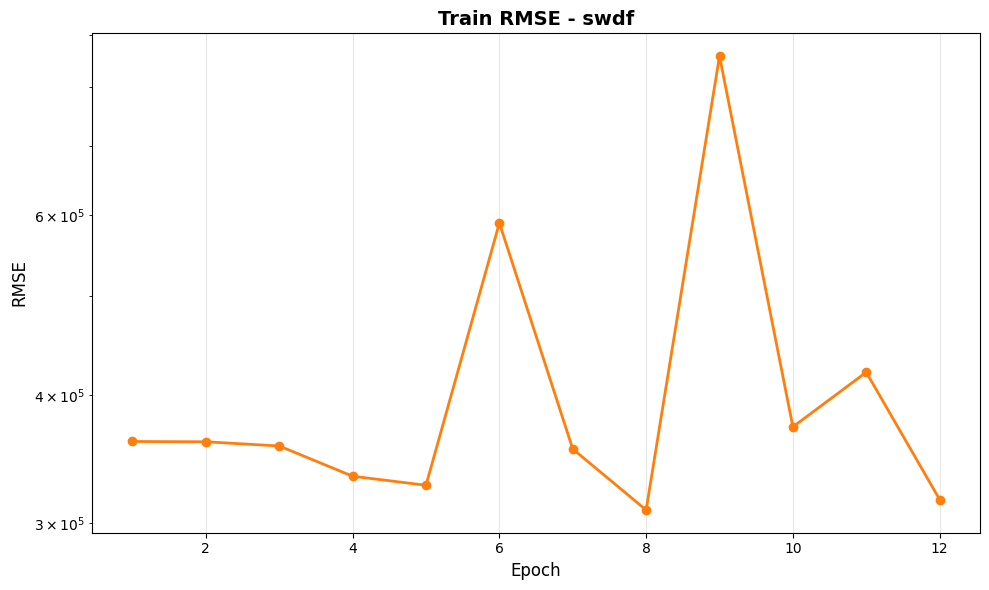

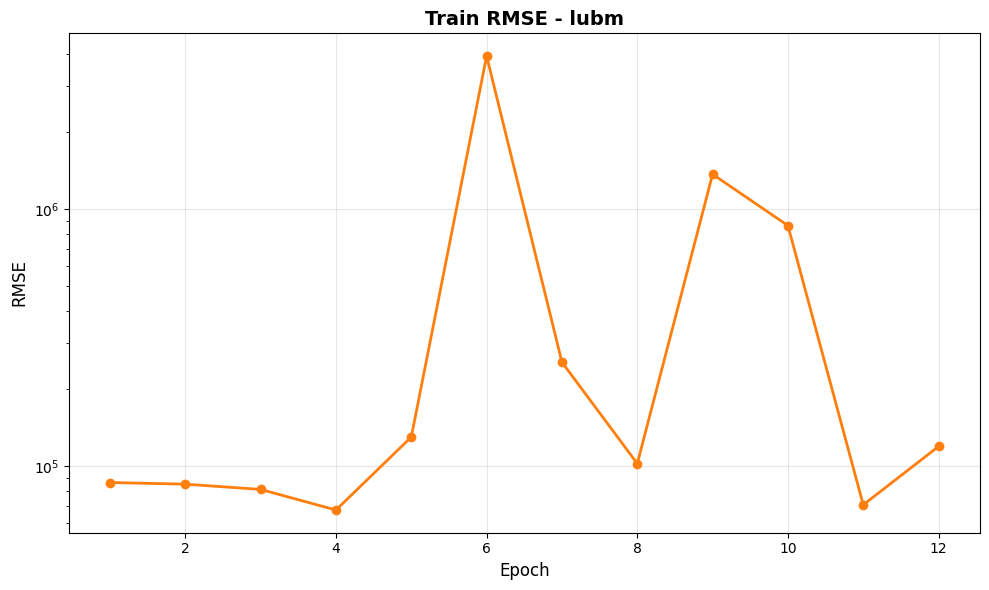

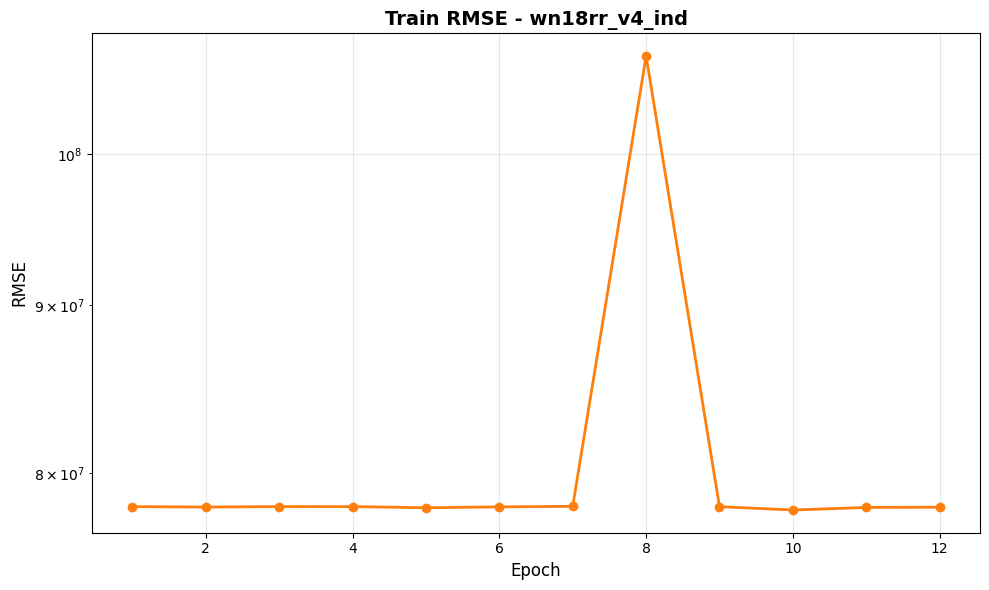

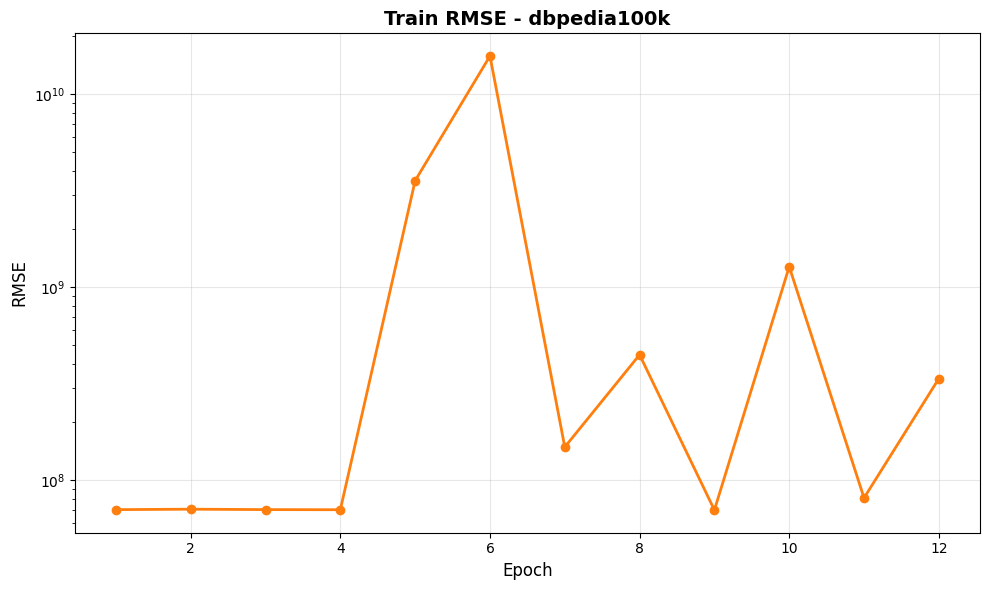

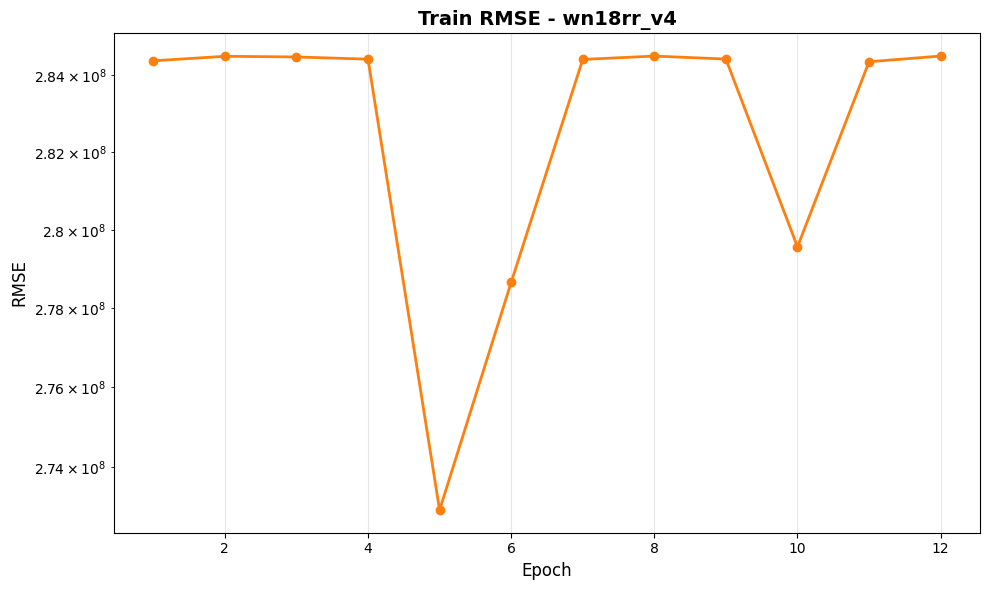

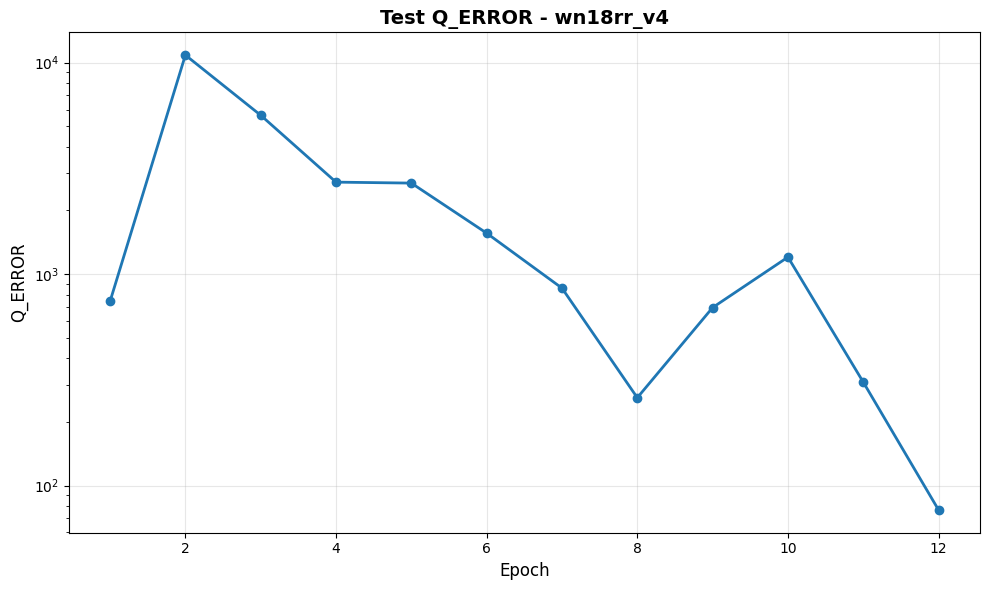

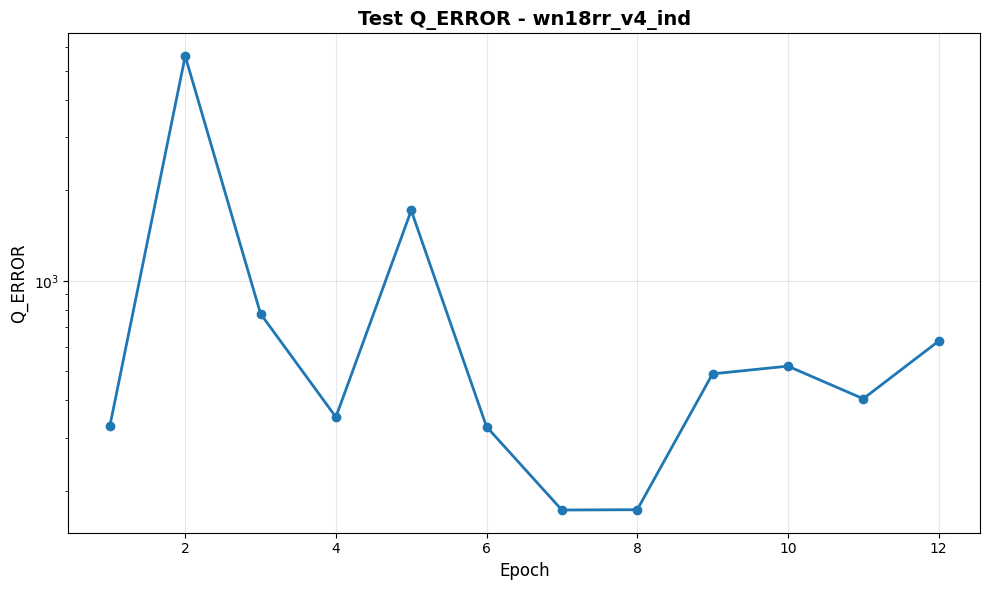

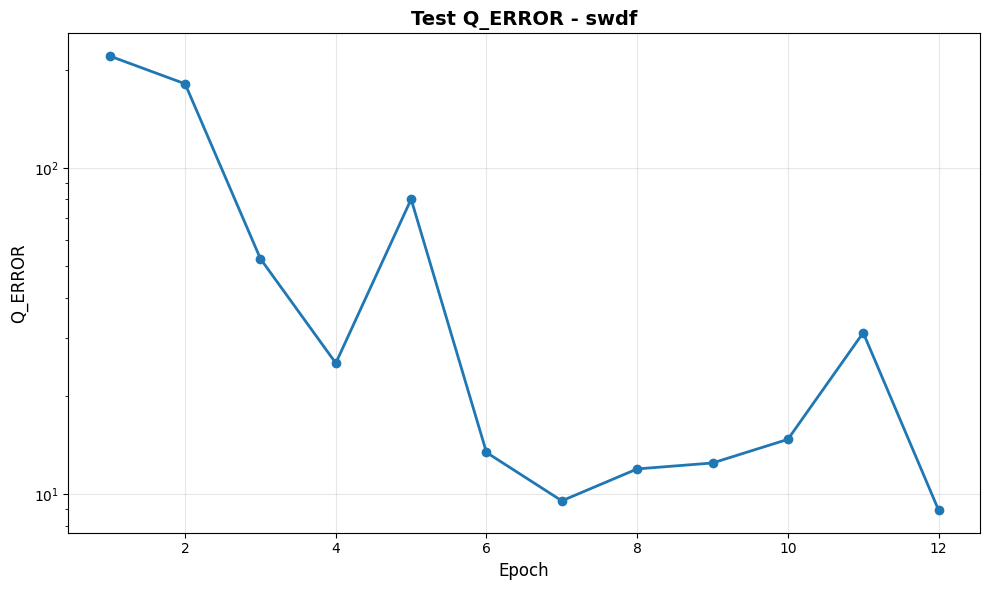

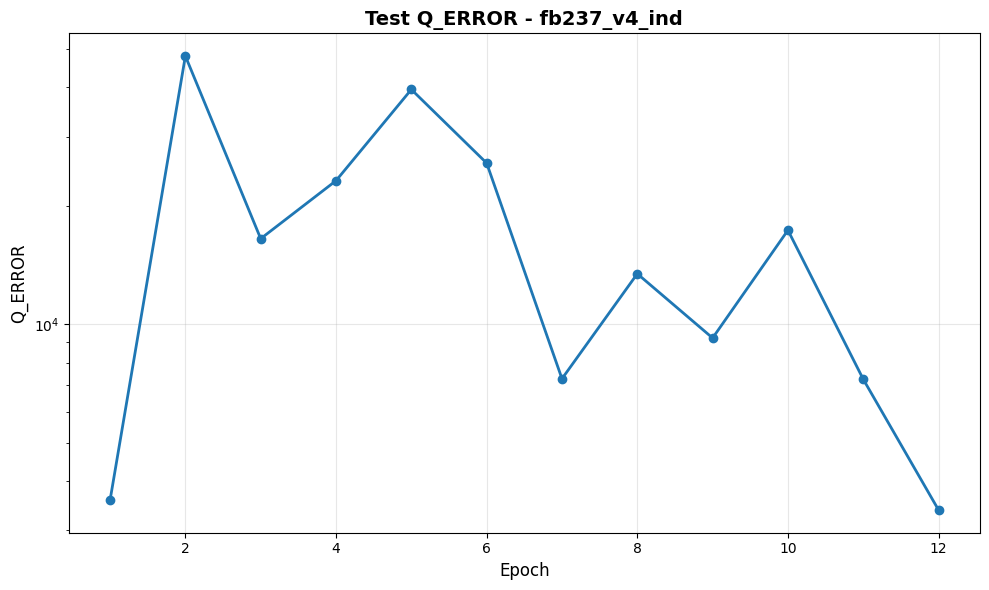

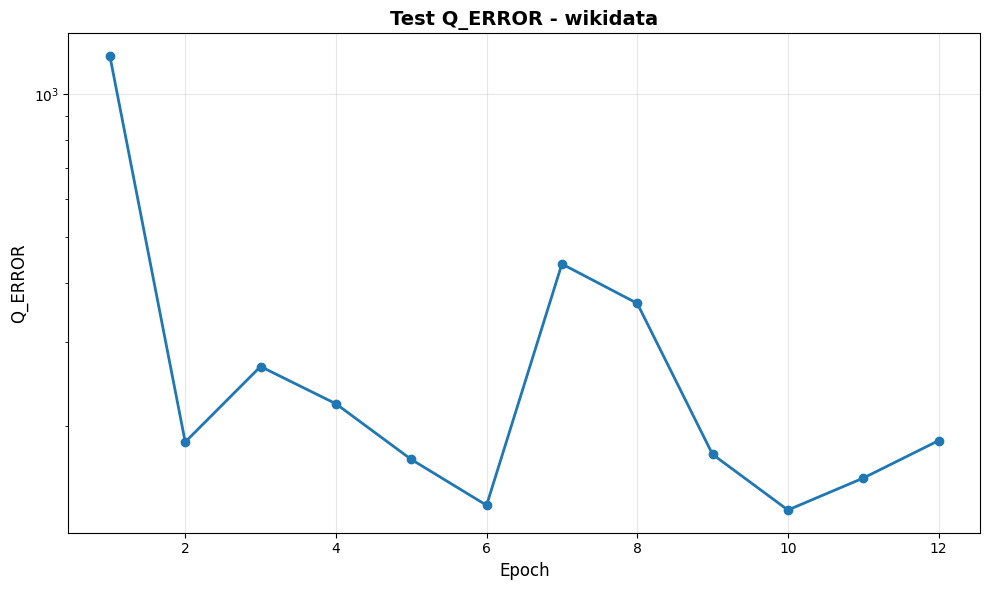

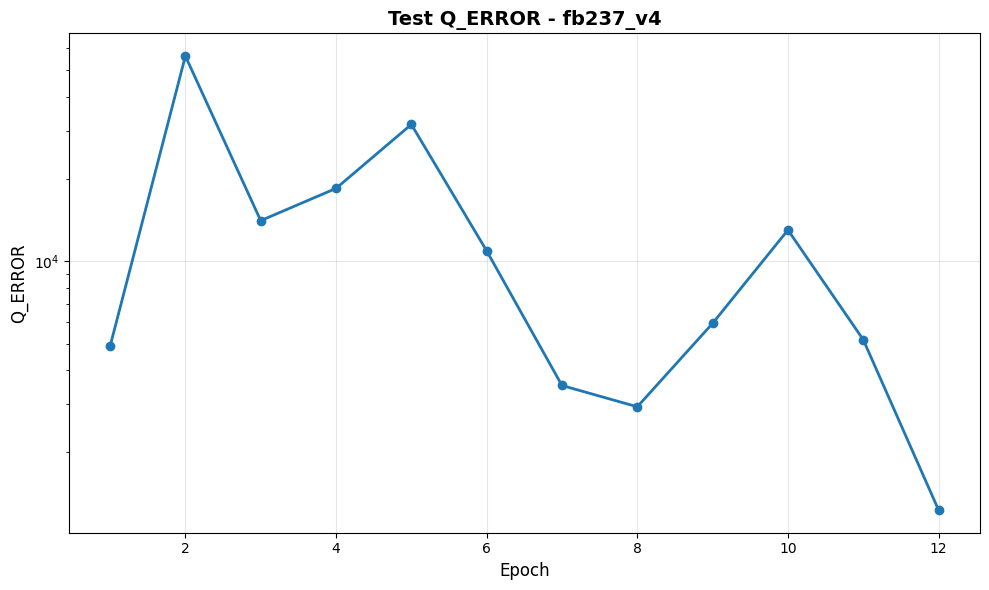

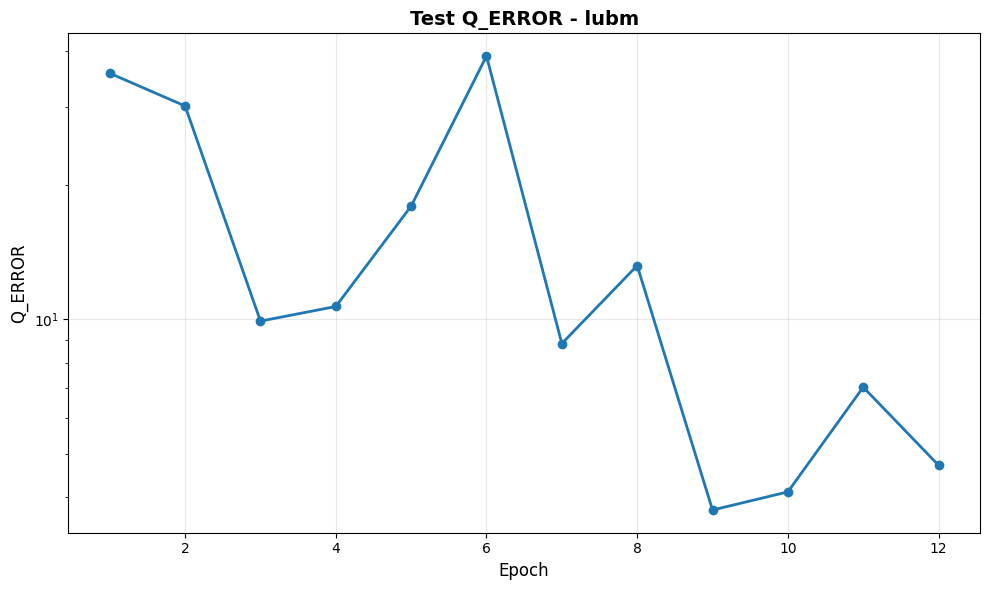

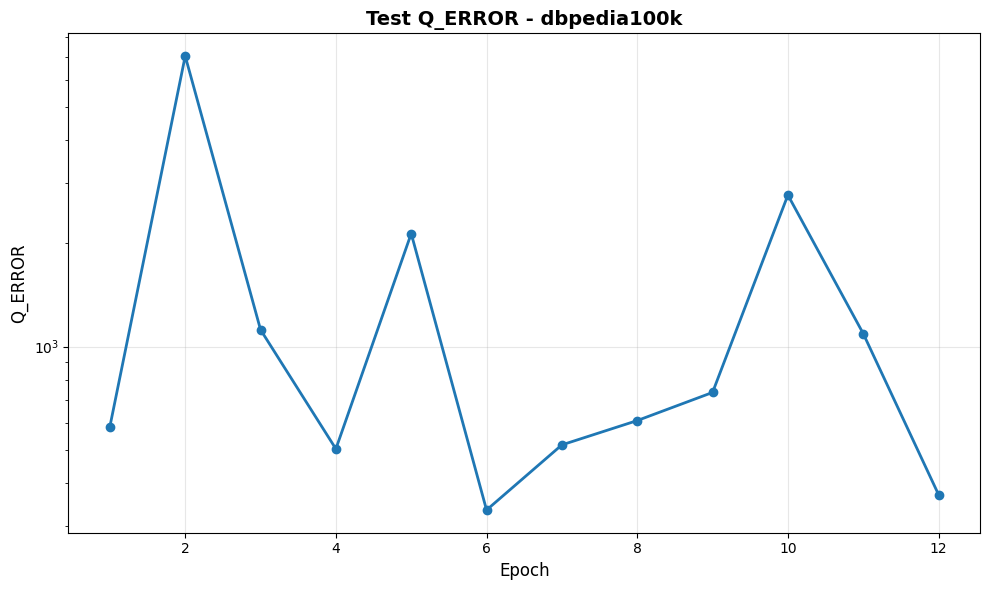

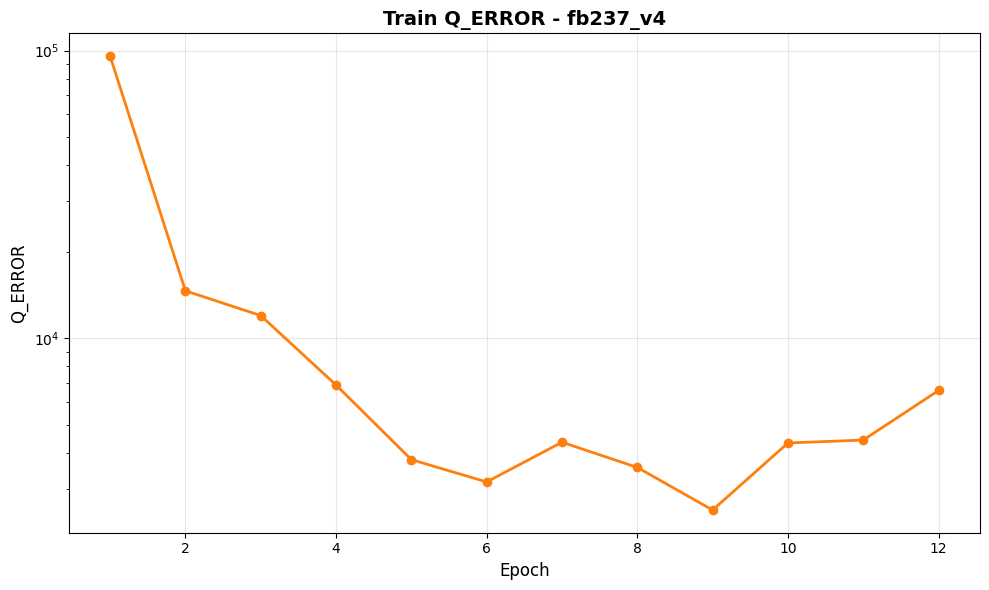

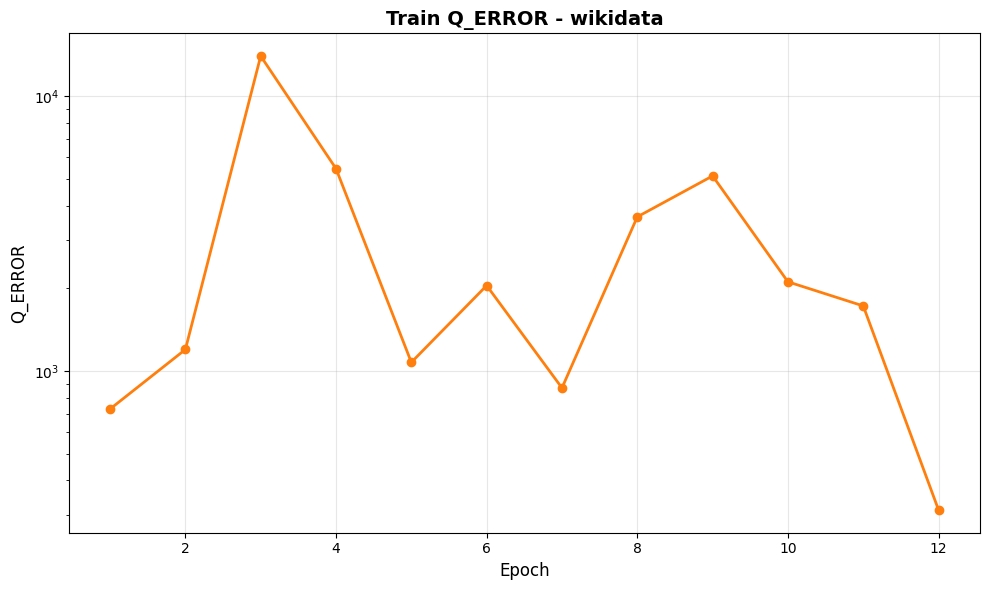

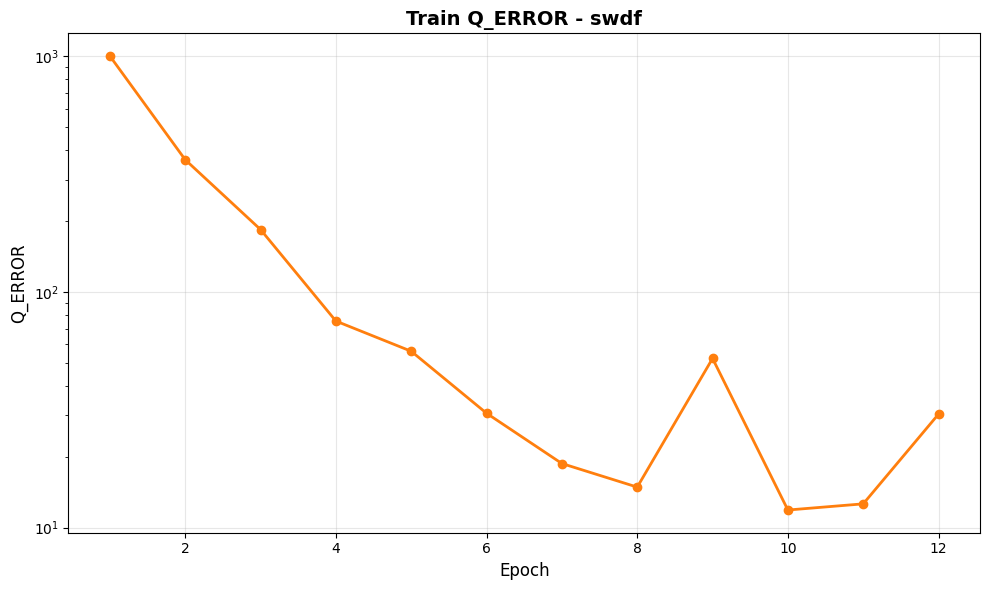

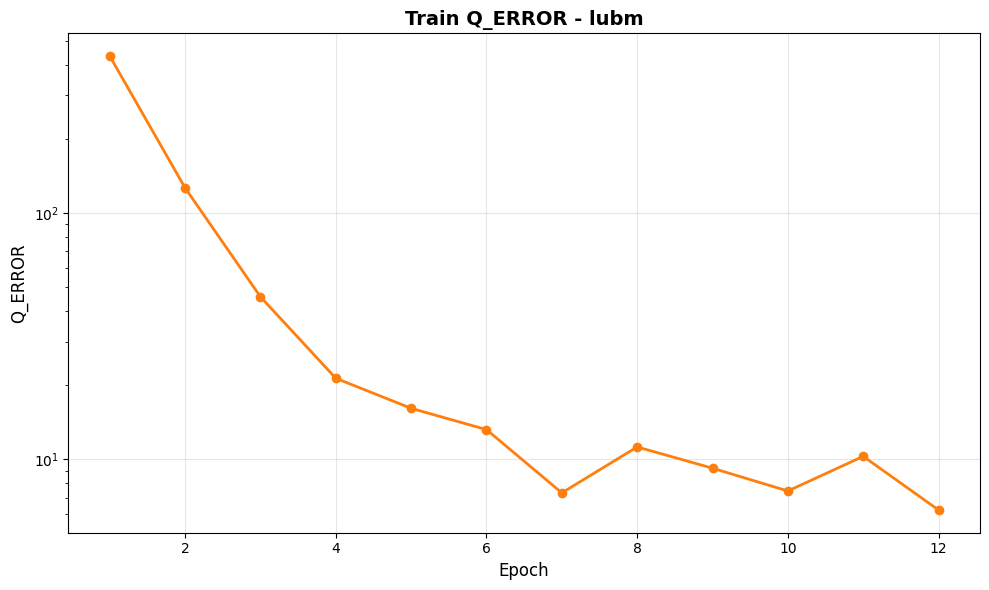

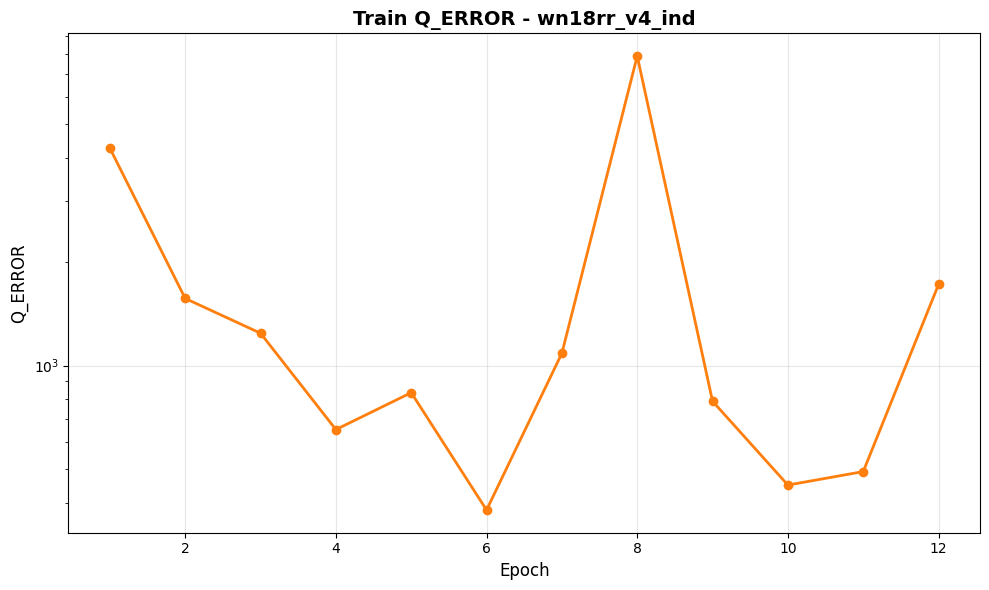

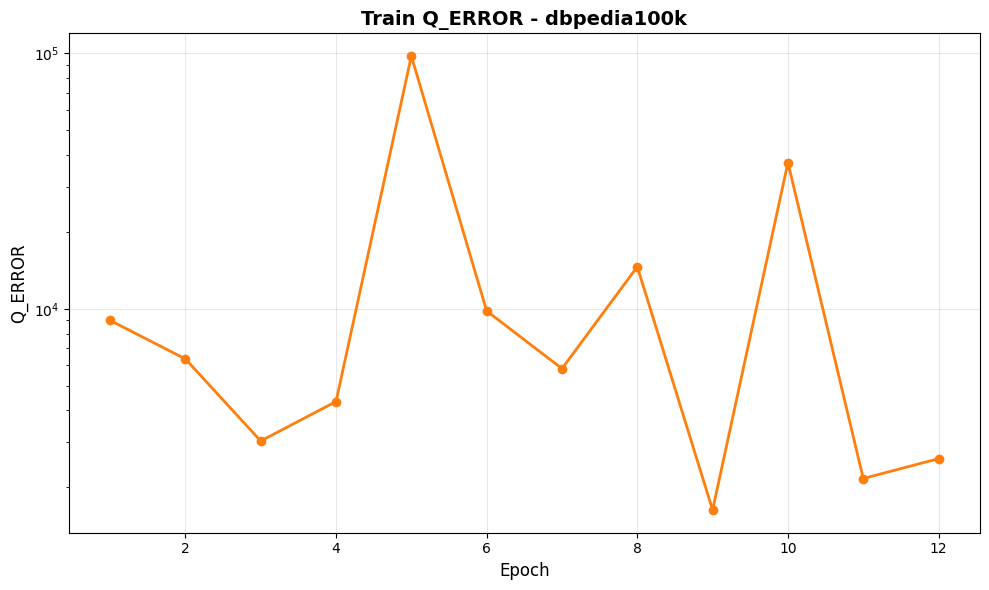

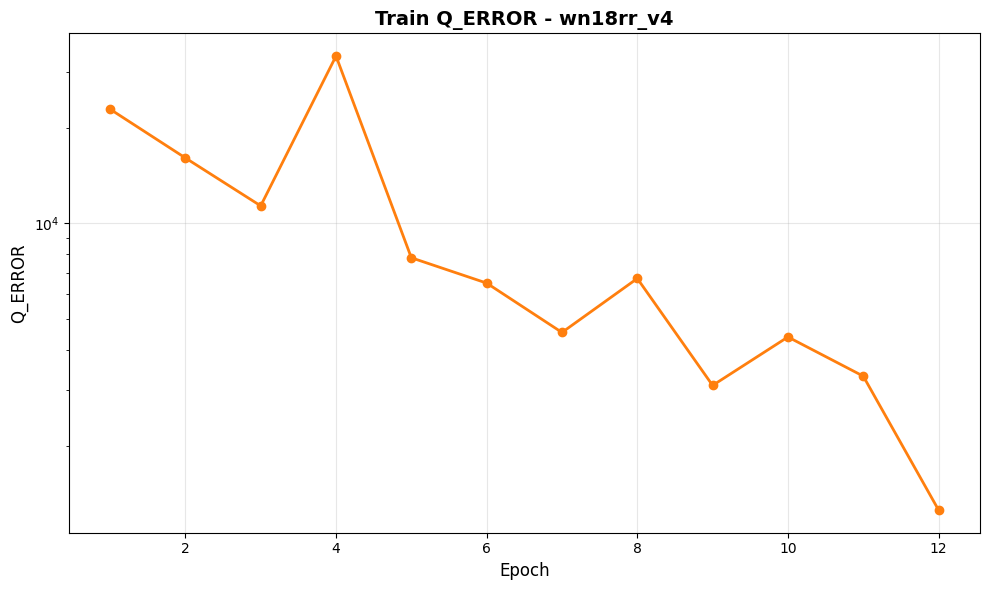

In [4]:
# Define metrics to plot
metrics = ['loss', 'mse', 'mae', 'rmse', 'q_error']

# Metrics that benefit from log scale due to large value ranges
log_scale_metrics = ['mse', 'rmse', 'q_error']

# Create plots for each metric and each dataset combination
for metric in metrics:
    # Test data - one figure per dataset
    for dataset in test_data['dataset_name'].unique():
        fig, ax = plt.subplots(figsize=(10, 6))
        
        dataset_data = test_data[test_data['dataset_name'] == dataset]
        ax.plot(dataset_data['epoch'], dataset_data[metric], marker='o', linewidth=2, markersize=6)
        
        ax.set_xlabel('Epoch', fontsize=12)
        ax.set_ylabel(metric.upper(), fontsize=12)
        ax.set_title(f'Test {metric.upper()} - {dataset}', fontsize=14, fontweight='bold')
        ax.grid(True, alpha=0.3)
        
        if metric in log_scale_metrics:
            ax.set_yscale('log')
        
        plt.tight_layout()
        plt.show()
    
    # Train data - one figure per dataset
    for dataset in train_data['dataset_name'].unique():
        fig, ax = plt.subplots(figsize=(10, 6))
        
        dataset_data = train_data[train_data['dataset_name'] == dataset]
        ax.plot(dataset_data['epoch'], dataset_data[metric], marker='o', linewidth=2, markersize=6, color='C1')
        
        ax.set_xlabel('Epoch', fontsize=12)
        ax.set_ylabel(metric.upper(), fontsize=12)
        ax.set_title(f'Train {metric.upper()} - {dataset}', fontsize=14, fontweight='bold')
        ax.grid(True, alpha=0.3)
        
        if metric in log_scale_metrics:
            ax.set_yscale('log')
        
        plt.tight_layout()
        plt.show()